# Context and objective

## Context

El peer-to-peer lending (préstamos entre particulares mediados por una plataforma) es un modelo financiero en el que inversionistas individuales fondean préstamos a otras personas, sin un banco tradicional de por medio. La plataforma que origina el préstamo asume el rol de evaluar el riesgo crediticio del solicitante y asignarle condiciones (monto, tasa, plazo). Para los inversionistas, el riesgo central es que el prestatario no pague el préstamo (incumplimiento o charge-off), lo que representa pérdida directa de capital.

## Data-driven problem

A partir de la información disponible en el momento de originar un préstamo (monto solicitado, ingresos declarados, historial crediticio, propósito del préstamo, plazo, etc.), ¿es posible anticipar si un préstamo terminará siendo pagado en su totalidad o incumplido?

Es medible porque el desenlace histórico de cada préstamo (loan_status) ya está registrado en los datos, y es concreto porque se reduce a una decisión binaria verificable: pagado vs. incumplido. El target es binario

## Type of learning and justification

Aprendizaje supervisado, clasificación binaria.

El problema cumple las condiciones para un enfoque supervisado: existe una variable objetivo históricamente registrada (loan_status), un volumen de datos suficiente (miles de casos con desenlace definitivo) y un conjunto de variables predictoras disponibles antes de conocerse el desenlace. No es un problema de reglas fijas: la relación entre perfil crediticio y riesgo de incumplimiento es multivariable y no lineal en varios de sus factores (por ejemplo, la interacción entre ingreso, deuda y propósito del préstamo), lo que justifica un enfoque de aprendizaje automático sobre reglas manuales simples.

# Dataset description

## Libraries

In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Source

LendingClub fue una plataforma estadounidense de prestamos peer-to-peer (P2P) que conectaba directamente a inversionistas individuales con solicitantes de credito personal, evaluando ella misma el riesgo y las condiciones de cada prestamo. Estos datos son el historico publico de los prestamos que la plataforma origino aproximadamente entre 2007 y 2018 (segun issue_d), publicados por LendingClub y distribuidos como mirror en Kaggle bajo el dataset adarshsng/lending-club-loan-data-csv, que es la fuente que se descarga a continuacion con kagglehub.

In [ ]:
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")

df = pd.read_csv(os.path.join(path, "loan.csv"), low_memory=False)

100%|██████████| 339M/339M [00:03<00:00, 89.1MB/s]

Extracting files...


## Size

*   **Dataset original:** 2,260,668 filas × 145 columnas.
*   **Reducción aplicada:** muestreo aleatorio reproducible de 30,000 filas (random_state=42) y selección manual de 20 columnas relevantes, para evitar fuga de datos y mantener el proyecto manejable en el semestre.
*   **Tamaño final tras limpieza del target:** 17,264 filas, una vez excluidos los préstamos sin desenlace definitivo (Current, Late, In Grace Period).

In [ ]:
print(df.shape)

(2260668, 145)


## Variables

In [ ]:
print(df.dtypes.value_counts()) # ¿Cuántas variables hay de cada tipo?
print(df.select_dtypes(include='number').columns.tolist()) # ¿Cuáles son numéricas?
print(df.select_dtypes(include='object').columns.tolist()) # ¿Cuáles son categóricas?

float64    105
object      36
int64        4
Name: count, dtype: int64
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'int_rate', 'installment', 'annual_inc', 'url', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_amnt', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'annual_inc_joint', 'dti_joint', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il', 'total_bal_il', 'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi', 'total_cu_tl', 'inq_last_12m', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths

## Relevance

Las 19 variables predictoras se seleccionaron manualmente de las 145 originales por dos criterios: (1) estar disponibles antes de conocerse el desenlace del préstamo, y (2) aportar información crediticia o financiera relevante para el riesgo de incumplimiento. Se excluyeron explícitamente columnas como total_pymnt, recoveries, last_pymnt_amnt y las variables settlement_*, porque solo existen o toman valor después de que el préstamo concluye, incluirlas constituiría fuga de datos.

In [ ]:
columnas_relevantes = [
    'loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti',
    'open_acc', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc',
    'term', 'grade', 'sub_grade', 'emp_length', 'home_ownership',
    'verification_status', 'purpose', 'application_type',
    'issue_d', 'loan_status'
]

df_reducido = df[columnas_relevantes].copy()

df = df_reducido.sample(n=30000, random_state=42)

numerical = df.select_dtypes(include='number').columns.tolist()
categorical = df.select_dtypes(include='object').columns.tolist()

Target

In [ ]:
estados_validos = ['Fully Paid', 'Charged Off']
df = df[df['loan_status'].isin(estados_validos)].copy()
df['default'] = (df['loan_status'] == 'Charged Off').astype(int)
print(df.shape)
print(df['default'].value_counts(normalize=True))

(17264, 21)
default
0    0.798714
1    0.201286
Name: proportion, dtype: float64


In [ ]:
print(df.dtypes.value_counts()) # ¿Cuántas variables hay de cada tipo?
print(numerical) # ¿Cuáles son numéricas?
print(categorical) # ¿Cuáles son categóricas?

object     10
float64     8
int64       3
Name: count, dtype: int64
['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc']
['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'application_type', 'issue_d', 'loan_status']


In [ ]:

fecha = ['issue_d']
categorical = [c for c in categorical if c not in fecha]
print('Numericas:', numerical)
print('Fecha:', fecha)
print('Categoricas:', categorical)

Numericas: ['loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc']
Fecha: ['issue_d']
Categoricas: ['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose', 'application_type', 'loan_status']


El target es la variable loan_status binarizado en Fully Paid vs Charged Off tras excluir estados no definitivos.

## Assumptions and limitations

*   **Supuesto de muestreo:** se trabaja sobre una muestra aleatoria reproducible de 30,000 filas del total de 2.26M, con semilla fija (random_state=42). Los resultados de este proyecto son representativos de esa muestra, no un análisis exhaustivo del dataset completo.
*   **Limitación temporal:** los préstamos corresponden a un rango histórico (aproximadamente 2013–2018 según lo observado en issue_d); el comportamiento de pago pudo estar influenciado por condiciones económicas de esa época que no necesariamente se repiten hoy.
*   **Limitación geográfica:** LendingClub opera en Estados Unidos; los hallazgos no son necesariamente generalizables a otros mercados o sistemas crediticios.
*   **Verificación de ingreso (verification_status):** annual_inc es un ingreso autoreportado, y no todos los casos fueron verificados por LendingClub. Un cruce con el target muestra un patrón contraintuitivo: los préstamos Not Verified tienen la tasa de incumplimiento más baja, mientras que Verified tiene la más alta, lo que sugiere que el propio proceso de verificación no es aleatorio. Por esta razón se decidió no filtrar el dataset a solo casos verificados y en su lugar mantener verification_status como variable categórica predictora, permitiendo que el modelo aproveche esta señal directamente.
*   **Sesgo potencial:** al ser un dataset de solicitantes ya aprobados por LendingClub, no representa a personas que solicitaron un préstamo y fueron rechazadas. El modelo solo puede aprender sobre el riesgo dentro de la población ya aceptada por la plataforma, no sobre la decisión de aceptar o rechazar en primer lugar.

# Data Diagnosis

## Missing values

In [ ]:
df.isnull().sum()

,0
loan_amnt,0
int_rate,0
installment,0
annual_inc,0
dti,5
open_acc,0
revol_bal,0
revol_util,7
total_acc,0
mort_acc,647


Los nulos son minoritarios y concentrados en dos columnas: emp_length (1,040 filas, 6.0% del total) y mort_acc (647 filas, 3.7%). dti y revol_util tienen nulos casi despreciables (5 y 7 filas respectivamente, menos del 0.05%). Ninguna columna supera el 10% de nulos, por lo que no se justifica eliminar variables completas; se manejaran con imputacion en la fase de preprocesamiento (ver Preprocessing Plan).

## Class balance

In [ ]:
print(df['default'].value_counts())
print(df['default'].value_counts(normalize=True) * 100)

default
0    13789
1     3475
Name: count, dtype: int64
default
0    79.871409
1    20.128591
Name: proportion, dtype: float64


El desbalance es moderado: 79.9% Fully Paid (0) vs 20.1% Charged Off (1), una razon aproximada de 4 a 1. No es un desbalance extremo, pero es suficiente para descartar accuracy como metrica principal de evaluacion en la fase de modelado; se prioriza recall, precision, F1 y AUC-ROC para la clase minoritaria.

## Duplicate values

In [ ]:
df.duplicated().sum()
df[df.duplicated(keep=False)]

,loan_amnt,int_rate,installment,annual_inc,dti,open_acc,revol_bal,revol_util,total_acc,mort_acc,...,grade,sub_grade,emp_length,home_ownership,verification_status,purpose,application_type,issue_d,loan_status,default


No hay.

## Inconsistent formats

In [ ]:
for col in df.columns:
  print(col, df[col].unique())

loan_amnt [35000 15000 24000 ... 26050 29875 27525]
int_rate [12.12  7.49 21.15  9.93 24.74 14.33 24.99  7.99 17.86 13.18 17.77  9.43
 12.29 20.   12.05  9.49 11.49 19.99 19.03 11.53 10.99  7.69 13.99 11.99
 13.33 15.61 16.29 13.58 16.99 18.24 26.49 20.49  8.39 18.25 14.99  8.9
 18.2  21.98  9.92 15.88 10.49 25.57 12.74 11.39 19.72 18.49 14.46  6.49
 12.85 15.99 23.99  8.19 14.31 12.69 25.82 11.47 10.74 15.31 15.1  13.98
 17.57 22.39  7.9   5.32 12.99 10.42  7.97  9.99 18.99 21.67 14.16  7.62
  6.68 14.3  16.55  8.59 14.09  8.99 12.59 25.99 24.49  7.39 13.66 26.14
  7.26  9.17  6.89 13.49  6.24  7.21 13.44 21.18  9.16 14.65 21.    7.89
  6.08 16.02 15.04 10.75 22.15 26.24  6.97 15.59  8.67 13.53 13.11 11.14
 15.8  19.05 19.89  8.24 18.92 17.99 13.05  7.96 11.48 20.99 16.59 12.35
 19.19 12.61 14.49  6.71 11.98  6.92  6.07 11.44  6.62 14.47 13.67 14.64
  6.03  6.39 11.11 17.09 18.55 16.14 20.75 25.8   5.42 10.78 11.26 13.56
 21.85 11.67  9.75 14.08 11.55 19.47 14.11 23.88 10.91 14.07  6.

Formatos inconsistentes: la columna term presenta valores con un espacio inicial, por ejemplo ' 36 months' y ' 60 months' en lugar de '36 months' y '60 months'. Esto es un problema de formato de texto, no de tipo de dato, y debe corregirse en el Preprocessing Plan aplicando strip antes de convertir la columna a un valor numerico.

## Data entry errors

In [ ]:
print('Valores de dti negativos:', (df['dti'] < 0).sum())
print('Valores de dti iguales a 999 (posible codigo centinela):', (df['dti'] == 999).sum())
print('Valores de annual_inc iguales a 0:', (df['annual_inc'] == 0).sum())
print('Valores de revol_util mayores a 100:', (df['revol_util'] > 100).sum())
print('Valores de loan_amnt menores o iguales a 0:', (df['loan_amnt'] <= 0).sum())

Valores de dti negativos: 0
Valores de dti iguales a 999 (posible codigo centinela): 0
Valores de annual_inc iguales a 0: 5
Valores de revol_util mayores a 100: 63
Valores de loan_amnt menores o iguales a 0: 0


No se encontraron valores de dti negativos ni valores centinela (999), ni loan_amnt menor o igual a 0. Se detectaron 5 filas con annual_inc igual a 0, lo cual es un valor poco creible para un solicitante de credito y debe tratarse como dato erroneo o revisarse en el Preprocessing Plan. Tambien se encontraron 63 filas con revol_util mayor a 100%, lo cual excede el rango logico de un porcentaje de utilizacion de credito revolvente (0-100%); estas filas se marcaran para limpieza o imputacion en la etapa de preprocesamiento.

## Wrong data types

Se identificaron las siguientes columnas con un tipo de dato que no corresponde a su naturaleza real y que deberan convertirse en el Preprocessing Plan: term esta almacenada como texto ( 36 months / 60 months) debiendo ser numerica tras limpiar el espacio y extraer el numero de meses; issue_d esta almacenada como texto (por ejemplo Jun-2013) debiendo convertirse a un tipo fecha; emp_length y sub_grade son variables categoricas con un orden implicito (ordinales), por lo que se recomienda codificarlas como variables ordinales en lugar de nominales.

## Potential outliers

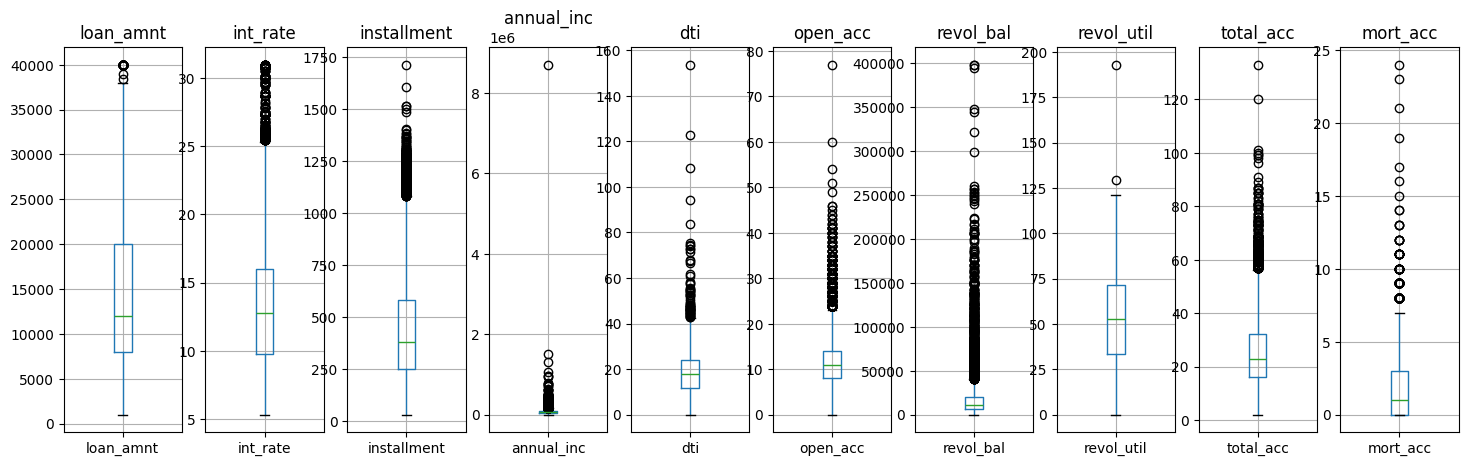

In [ ]:
plt.figure(figsize=(18,5))
for col in numerical:
    plt.subplot(1,len(numerical),numerical.index(col)+1)
    df.boxplot(column=col)
    plt.title(col)

In [ ]:
for col in numerical:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    pct = round(100 * outliers / len(df), 2)
    print(col, ':', outliers, 'valores atipicos, ', pct, '%')

loan_amnt : 88 valores atipicos,  0.51 %
int_rate : 288 valores atipicos,  1.67 %
installment : 505 valores atipicos,  2.93 %
annual_inc : 838 valores atipicos,  4.85 %
dti : 59 valores atipicos,  0.34 %
open_acc : 605 valores atipicos,  3.5 %
revol_bal : 1004 valores atipicos,  5.82 %
revol_util : 2 valores atipicos,  0.01 %
total_acc : 315 valores atipicos,  1.82 %
mort_acc : 206 valores atipicos,  1.19 %


Se cuantificaron los valores atipicos de cada variable numerica usando el criterio de rango intercuartilico (IQR): un valor se considera atipico si esta por debajo de Q1 menos 1.5 veces el IQR o por encima de Q3 mas 1.5 veces el IQR. Las variables con mayor proporcion de valores atipicos son revol_bal (5.82%), annual_inc (4.85%) y open_acc (3.5%), lo cual es consistente con la naturaleza de estas variables financieras, que suelen tener distribuciones sesgadas a la derecha con colas largas de clientes con ingresos o saldos muy altos. revol_util presenta muy pocos valores atipicos bajo este criterio (0.01%), aunque como se vio en Data entry errors, 63 filas superan el limite logico de 100%. Estos hallazgos se tendran en cuenta en el Preprocessing Plan, evaluando si estos valores se tratan como atipicos legitimos (no se eliminan) o como errores de captura (se corrigen o eliminan), y si se aplican transformaciones como escalado robusto o logaritmico para reducir su impacto en el modelo.

# Exploratory Data Analysis

En esta seccion se realiza un analisis exploratorio de los datos ya diagnosticados, con el objetivo de entender la distribucion de las variables individuales, las relaciones entre pares de variables y su relacion con la variable objetivo default, para justificar las decisiones que se tomaran en el Preprocessing Plan y en la seleccion del enfoque de Machine Learning.


## Univariate

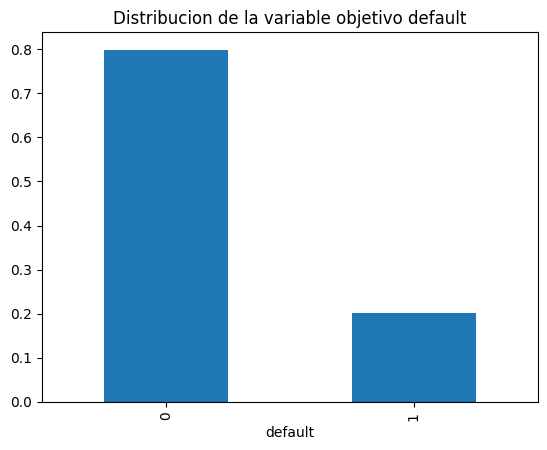

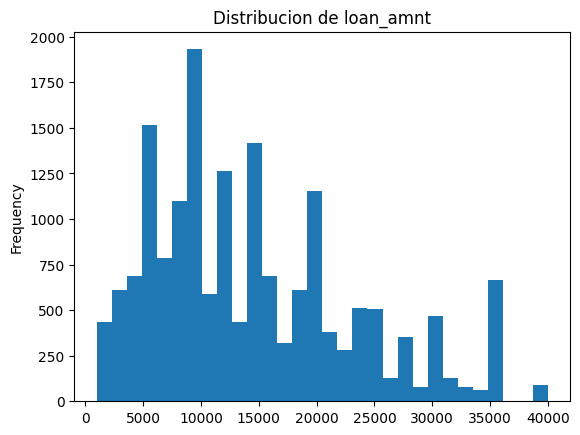

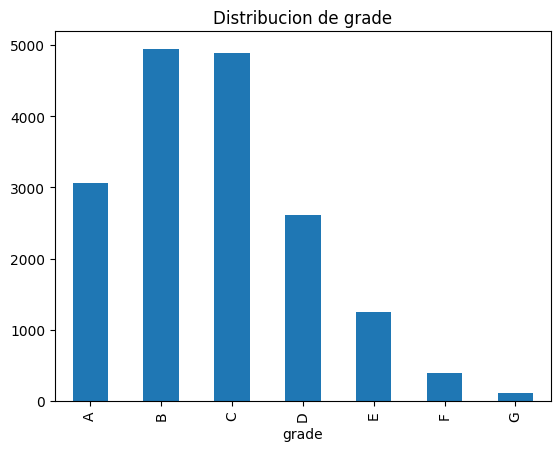

In [ ]:
df['default'].value_counts(normalize=True).plot(kind='bar')
plt.title('Distribucion de la variable objetivo default')
plt.show()
df['loan_amnt'].plot(kind='hist', bins=30)
plt.title('Distribucion de loan_amnt')
plt.show()
df['grade'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribucion de grade')
plt.show()

La variable objetivo default confirma el desbalance de clases ya detectado en el diagnostico (aproximadamente 80% Fully Paid frente a 20% Charged Off). La variable loan_amnt muestra una distribucion sesgada a la derecha, con la mayoria de los prestamos concentrados entre 5,000 y 20,000, y una cola de montos mayores que coincide con los valores atipicos identificados por IQR. La variable grade muestra que la mayoria de los prestamos se concentran en las categorias A, B y C, con una caida progresiva hacia las categorias de mayor riesgo (D a G), lo cual es consistente con una entidad que otorga credito principalmente a perfiles de riesgo bajo o medio.

## Bivariate

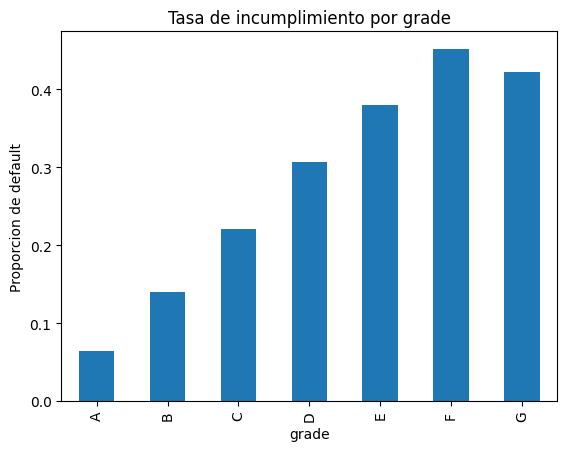

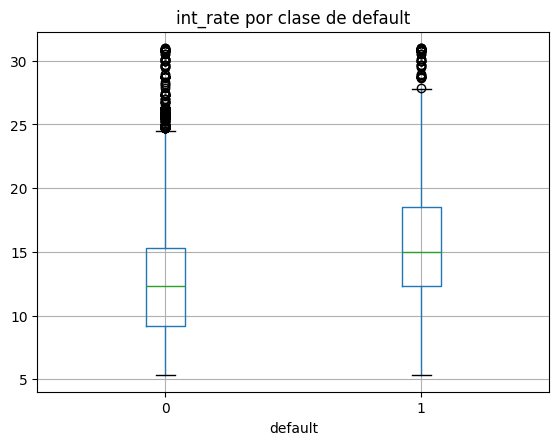

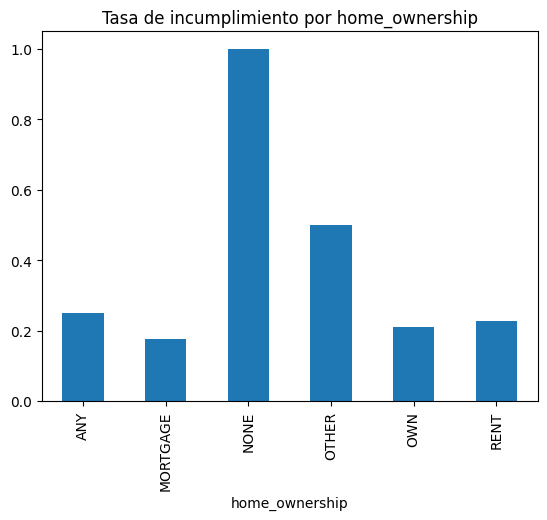

In [ ]:
df.groupby('grade')['default'].mean().sort_index().plot(kind='bar')
plt.title('Tasa de incumplimiento por grade')
plt.ylabel('Proporcion de default')
plt.show()
df.boxplot(column='int_rate', by='default')
plt.title('int_rate por clase de default')
plt.suptitle('')
plt.show()
df.groupby('home_ownership')['default'].mean().sort_index().plot(kind='bar')
plt.title('Tasa de incumplimiento por home_ownership')
plt.show()

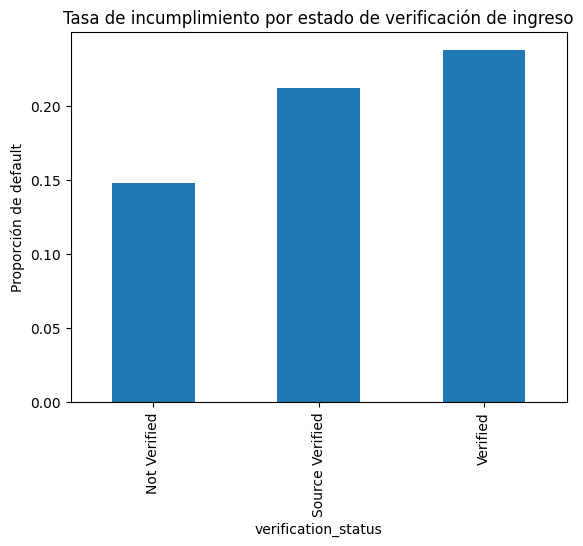

In [ ]:
df.groupby('verification_status')['default'].mean().sort_values().plot(kind='bar')
plt.title('Tasa de incumplimiento por estado de verificación de ingreso')
plt.ylabel('Proporción de default')
plt.show()

Contrario a lo esperado, los préstamos Not Verified muestran la tasa de incumplimiento más baja, mientras que Verified muestra la más alta. Esto sugiere que el propio proceso de verificación de LendingClub no es aleatorio, sino que se aplica con más rigor a solicitantes ya percibidos como más riesgosos; no necesariamente que el ingreso no verificado sea menos confiable. Por esta razón se decide mantener verification_status como variable categórica predictora en lugar de filtrar el dataset a solo casos verificados.

La tasa de incumplimiento (proporcion de default) aumenta de forma clara y monotona a medida que empeora el grade, desde las categorias A hasta G, lo cual confirma que grade es una variable con fuerte poder predictivo y coincide con su proposito original como medida de riesgo crediticio. El boxplot de int_rate por clase de default muestra que los prestamos que terminan en Charged Off (default = 1) tienen, en general, tasas de interes mas altas que los que se pagan por completo, lo cual es consistente con que una tasa mayor suele asignarse a solicitantes de mayor riesgo. En cuanto a home_ownership, las categorias RENT, OWN y MORTGAGE muestran tasas de incumplimiento similares (alrededor de 0.2), mientras que NONE y OTHER muestran tasas notablemente mas altas; sin embargo, estas dos categorias tienen muy pocas observaciones en el dataset, por lo que esta diferencia debe interpretarse con cautela y se validara con mas detalle en el segundo semestre del proyecto.

## Multivariate

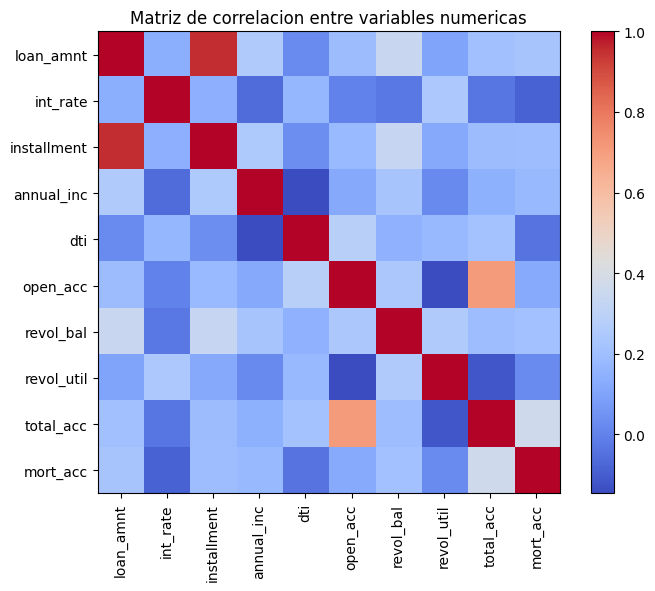

             loan_amnt  int_rate  installment  annual_inc   dti  open_acc  \
loan_amnt         1.00      0.14         0.95        0.26  0.03      0.19   
int_rate          0.14      1.00         0.14       -0.06  0.17     -0.00   
installment       0.95      0.14         1.00        0.25  0.03      0.18   
annual_inc        0.26     -0.06         0.25        1.00 -0.15      0.12   
dti               0.03      0.17         0.03       -0.15  1.00      0.29   
open_acc          0.19     -0.00         0.18        0.12  0.29      1.00   
revol_bal         0.34     -0.03         0.33        0.23  0.15      0.24   
revol_util        0.10      0.25         0.12        0.02  0.18     -0.15   
total_acc         0.21     -0.03         0.19        0.15  0.22      0.71   
mort_acc          0.23     -0.08         0.19        0.18 -0.04      0.13   

             revol_bal  revol_util  total_acc  mort_acc  
loan_amnt         0.34        0.10       0.21      0.23  
int_rate         -0.03        0.25  

In [ ]:
corr = df[numerical].corr()
plt.figure(figsize=(8,6))
plt.imshow(corr, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Matriz de correlacion entre variables numericas')
plt.show()
print(corr.round(2))

La matriz de correlacion muestra que la relacion mas fuerte entre variables numericas es la de loan_amnt con installment (0.95), lo cual es esperable ya que installment se calcula directamente a partir de loan_amnt, int_rate y term; esto debe tenerse en cuenta en el Preprocessing Plan para evitar redundancia y multicolinealidad en el modelo. La segunda relacion mas fuerte es open_acc con total_acc (0.71), ambas relacionadas con el numero de cuentas de credito del solicitante. El resto de las correlaciones entre variables numericas son debiles (por debajo de 0.35 en valor absoluto), lo que indica que, en general, estas variables aportan informacion relativamente independiente entre si y no se anticipan problemas graves de multicolinealidad fuera del par loan_amnt / installment.

# Preprocessing Plan

En este primer semestre se presenta unicamente la propuesta del plan de preprocesamiento, sin ejecutar transformaciones sobre los datos; las decisiones se justifican con base en los hallazgos del diagnostico de datos y del analisis exploratorio realizados anteriormente. La implementacion completa (ajuste de transformadores, particion train/test, pipeline, etc.) se realizara en el segundo semestre del proyecto.

## Data Cleaning

Con base en los hallazgos de Data Diagnosis y del analisis exploratorio, se proponen las siguientes acciones de limpieza. Valores de annual_inc iguales a 0 (5 filas): dado que es un numero muy pequeño de filas y un valor poco creible para un solicitante de credito, se propone tratarlas como dato faltante e imputarlas junto con el resto de valores atipicos de annual_inc, en lugar de eliminarlas. Valores de revol_util superiores a 100% (63 filas): se propone recortarlas (clip) al maximo logico de 100%, ya que se interpretan como errores de captura mas que como atipicos legitimos. Formato del texto en term: aplicar strip para eliminar el espacio inicial y extraer unicamente el numero de meses, convirtiendola en una variable numerica. Formato de issue_d: convertir la columna a tipo fecha usando pd.to_datetime.

## Numerical Features

Imputacion de valores faltantes: mort_acc (3.7% de nulos) se imputara con la mediana o, alternativamente, con un valor estimado a partir de su relacion con total_acc, dado que ambas variables estan moderadamente correlacionadas (0.36); dti y revol_util, con un porcentaje de nulos negligible (menos del 0.1%), se imputaran con la mediana.

Escalado: dado que varias variables numericas (annual_inc, revol_bal, open_acc) presentan distribuciones sesgadas y una proporcion relevante de valores atipicos segun el analisis IQR, se propone usar un escalador robusto (basado en mediana y rango intercuartilico) en lugar de un escalador estandar, para reducir la sensibilidad a los valores extremos. Para variables con sesgo muy pronunciado, como annual_inc, se evaluara adicionalmente una transformacion logaritmica antes del escalado. Reduccion de redundancia: dado que loan_amnt e installment presentan una correlacion muy alta (0.95), se evaluara conservar solo una de las dos variables, para evitar multicolinealidad en los modelos que sean sensibles a ella.

## Categorical Features

Variables ordinales: grade, sub_grade y emp_length tienen un orden implicito, por lo que se propone codificarlas con un esquema ordinal (por ejemplo, mapeando A a G y sus subgrados a numeros consecutivos, y los rangos de emp_length a valores crecientes), en lugar de un one-hot encoding, para conservar la relacion de orden entre categorias. Variables nominales: home_ownership, verification_status, purpose y application_type no tienen un orden natural, por lo que se propone codificarlas mediante one-hot encoding; en el caso de purpose, que tiene varias categorias con pocas observaciones, se evaluara agrupar las categorias menos frecuentes en una categoria unica de tipo otros para evitar generar demasiadas columnas dispersas. Categorias con pocas observaciones: home_ownership incluye las categorias NONE y OTHER con muy pocos registros, segun lo observado en el analisis bivariado; se evaluara agruparlas junto con OTHER o con la categoria mas cercana, para evitar categorias con muy pocas observaciones en la particion de entrenamiento.

# Machine Learning Approach

Esta seccion describe el enfoque de modelado que se plantea para el problema de clasificacion binaria (prediccion de default), incluyendo los modelos candidatos y la estrategia de evaluacion propuestos. No se entrena ni se ajusta ningun modelo en este primer semestre; el entrenamiento, la comparacion de modelos y el ajuste de hiperparametros se realizaran en el segundo semestre del proyecto.

## Model Selection

Se proponen tres modelos candidatos para el problema de clasificacion binaria (default vs no default). Regresion logistica: se propone como modelo base por su simplicidad, interpretabilidad y porque sus coeficientes permiten entender la direccion y magnitud del efecto de cada variable sobre el riesgo de incumplimiento, algo valioso en un contexto de riesgo crediticio donde la explicabilidad es importante. Random Forest: se propone como modelo de conjunto capaz de capturar relaciones no lineales e interacciones entre variables (por ejemplo, entre grade e int_rate) que la regresion logistica no captura facilmente, ademas de ser relativamente robusto frente a valores atipicos como los identificados en el diagnostico de datos. Gradient Boosting (por ejemplo XGBoost o similar): se propone como modelo de mayor capacidad predictiva, ampliamente usado en problemas de scoring crediticio sobre datos tabulares, y que permite manejar el desbalance de clases mediante ponderacion de clases o del parametro correspondiente. Estos tres modelos cubren un espectro que va desde uno simple e interpretable hasta modelos mas complejos con mayor poder predictivo, lo cual permitira comparar desempeño frente a interpretabilidad en el segundo semestre.

## Evaluation Strategy

Metricas: dado el desbalance de clases confirmado en el diagnostico (aproximadamente 80% Fully Paid frente a 20% Charged Off), no se usara accuracy como metrica principal, ya que un modelo que prediga siempre la clase mayoritaria obtendria un accuracy alto sin ser util. Se propone usar principalmente recall y precision de la clase minoritaria (default), el F1-score y el AUC-ROC, complementados con la matriz de confusion para entender el tipo de errores cometidos (falsos positivos frente a falsos negativos), lo cual es relevante en un contexto de riesgo crediticio donde ambos tipos de error tienen costos distintos. Particion y validacion: se propone dividir los datos en conjuntos de entrenamiento y prueba de forma estratificada (por ejemplo 80/20) para preservar la proporcion de clases, y usar validacion cruzada estratificada (k-fold, por ejemplo con k=5) sobre el conjunto de entrenamiento para comparar los modelos candidatos de forma mas robusta antes de evaluar en el conjunto de prueba. Criterios de sobreajuste: se comparara el desempeño de cada modelo entre el conjunto de entrenamiento y el de validacion o prueba; una diferencia grande (por ejemplo, un F1 o AUC-ROC notablemente mayor en entrenamiento que en validacion) se interpretara como señal de sobreajuste, lo que llevara a ajustar la complejidad del modelo (por ejemplo, profundidad de los arboles o regularizacion) en el segundo semestre.

# Second Term: Implementation

# Context and Continuity

## Context and problem restatement

Esta segunda parte implementa la propuesta formulada en el primer semestre. Se mantienen el mismo dataset (LendingClub, mirror adarshsng/lending-club-loan-data-csv), la misma muestra reproducible (30,000 filas con random_state=42, de las que quedan 17,264 préstamos con desenlace definitivo), las mismas 19 variables predictoras y la misma variable objetivo.

**Contexto.** En el peer-to-peer lending, inversionistas individuales fondean préstamos a personas a través de una plataforma que evalúa el riesgo del solicitante y fija las condiciones del crédito (monto, tasa y plazo). Para el inversionista, el riesgo central es que el préstamo termine en incumplimiento (Charged Off), lo que significa pérdida directa de capital.

**Problema.** Con la información disponible en el momento de originar un préstamo, ¿es posible anticipar si terminará pagado en su totalidad (Fully Paid, default = 0) o incumplido (Charged Off, default = 1)?

## Type of learning and expected outcomes

**Tipo de aprendizaje: supervisado (predictivo), clasificación binaria.** Existe una variable objetivo histórica y verificable (loan_status, binarizada en default), un volumen suficiente de casos etiquetados y un conjunto de variables conocidas antes del desenlace. El objetivo no es descubrir grupos, sino predecir una etiqueta conocida, por lo que el enfoque supervisado es el adecuado.

**Resultados esperados**, según los criterios definidos en el primer semestre:
*   Un modelo que identifique una proporción relevante de los préstamos que terminan en default (recall de la clase 1), algo que un modelo trivial que siempre predice "paga" no logra (recall = 0, aunque su accuracy sea cercano al 80%).
*   Un AUC-ROC de al menos 0.70, valor que se considera aceptable en modelos de scoring crediticio.
*   Comparar si los modelos de mayor capacidad (Random Forest y XGBoost) superan a la regresión logística, que funciona como línea base interpretable.
*   Entender qué variables explican el riesgo, para responder el problema con evidencia y no solo con una métrica.

## Changes with respect to the first term

El problema, el dataset, la muestra, el target y los tres modelos se mantienen. Los cambios son refinamientos de implementación y se justifican así:

| Decisión | Primer semestre | Segundo semestre | Justificación |
|---|---|---|---|
| Escalado | RobustScaler, con log en annual_inc | log en annual_inc y revol_bal, luego StandardScaler | El log ya controla las colas largas que motivaban RobustScaler, y PCA/LDA requieren variables estandarizadas (media 0, varianza 1). |
| Desbalance | scale_pos_weight ≈ 3.97 (solo XGBoost) | SMOTE aplicado solo sobre los datos de entrenamiento | Es una técnica vista en clase que se aplica igual a los tres modelos, lo que permite compararlos en condiciones iguales. Nunca se aplica sobre validación ni test. |
| Validación | 80/20 estratificado + 5-fold estratificado | Igual, pero imputación, escalado, reducción y SMOTE se ajustan dentro de cada fold | Evita fuga de datos: ningún paso del preprocesamiento "ve" los datos con los que se evalúa. |
| Nulos de emp_length | No se definió el tratamiento | Codificación ordinal (0 a 10) e imputación con la mediana del train | Completa el plan con un criterio consistente con el resto de variables numéricas. |
| Variables redundantes | Se "evaluaría" eliminar loan_amnt o installment | Se elimina installment (r = 0.95 con loan_amnt) y grade (r = 0.976 con sub_grade) | installment se calcula a partir de loan_amnt, int_rate y term. Toda la información de grade ya está contenida en sub_grade. |
| Nueva variable | No contemplada | loan_to_income = loan_amnt / annual_inc | Mide el tamaño del préstamo frente a la capacidad de pago y se relaciona con el default más que cada variable por separado. |
| issue_d | Convertir a fecha | Convertida a fecha y usada solo en el EDA, no como predictor | Un préstamo futuro no comparte la "época" de los datos históricos, y los préstamos recientes tienen sesgo de supervivencia (ver EDA). |
| Reducción de dimensionalidad | No aplicaba | PCA (y LDA como complemento) | Es requisito de esta fase. Su impacto se evalúa con validación cruzada. |
| Métricas | Recall, Precision, F1, AUC-ROC y matriz de confusión | Se agrega Accuracy | Lo exige la rúbrica. Se reporta, pero no se usa para elegir el modelo, por el desbalance de clases. |

## Libraries

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import joblib

# Data Cleaning

En esta sección se ejecuta el plan de limpieza propuesto en el primer semestre. Cada tratamiento reporta cuántas filas o columnas afectó y se compara con los conteos del diagnóstico de la fase 1. Se trabaja sobre una copia (df_clean) para no modificar el df original del diagnóstico.

Importante: la imputación de nulos **no** se hace aquí sobre todo el dataset, sino después de la partición train/test, usando solo las medianas del conjunto de entrenamiento. Así se evita que información del test se filtre al modelo.

In [ ]:
df_clean = df.copy()
print('Filas y columnas iniciales:', df_clean.shape)

Filas y columnas iniciales: (17264, 21)


## Duplicate values

In [ ]:
print('Filas duplicadas:', df_clean.duplicated().sum())

Filas duplicadas: 0


Se confirma lo reportado en la fase 1: **0 filas duplicadas**. No se requiere ningún tratamiento (0 filas afectadas).

## Inconsistent formats

In [ ]:
print('Valores de term antes:', df_clean['term'].unique())
df_clean['term'] = df_clean['term'].str.strip()
print('Valores de term despues:', df_clean['term'].unique())
print('Filas corregidas:', len(df_clean))

Valores de term antes: [' 36 months' ' 60 months']
Valores de term despues: ['36 months' '60 months']
Filas corregidas: 17264


Como se detectó en la fase 1, term tenía un espacio inicial (' 36 months', ' 60 months'). Se aplicó strip() a la columna completa, lo que afectó las **17,264 filas**. Ahora solo existen los valores '36 months' y '60 months'.

## Wrong data types

In [ ]:
df_clean['term'] = df_clean['term'].str.replace(' months', '').astype(int)
df_clean['issue_d'] = pd.to_datetime(df_clean['issue_d'], format='%b-%Y')

print(df_clean[['term', 'issue_d']].dtypes)
print('Fechas no convertidas:', df_clean['issue_d'].isnull().sum())
print('Rango de fechas:', df_clean['issue_d'].min(), 'a', df_clean['issue_d'].max())

term                int64
issue_d    datetime64[ns]
dtype: object
Fechas no convertidas: 0
Rango de fechas: 2007-09-01 00:00:00 a 2018-12-01 00:00:00


*   **term**: pasa de texto a entero (36 o 60 meses), para que el modelo la trate como una magnitud (plazo más largo) y no como texto. Afecta las 17,264 filas.
*   **issue_d**: pasa de texto ('Jun-2013') a fecha con pd.to_datetime y el formato '%b-%Y'. Las 17,264 fechas se convirtieron sin errores (0 nulos generados). El rango real es de septiembre de 2007 a diciembre de 2018, aunque el 88.9% de los préstamos se concentra entre 2013 y 2017.
*   **grade, sub_grade y emp_length**: son ordinales. Su codificación numérica se hace en Feature Engineering.

## Data entry errors

In [ ]:
print('annual_inc igual a 0:', (df_clean['annual_inc'] == 0).sum())
print('revol_util mayor a 100:', (df_clean['revol_util'] > 100).sum())

df_clean.loc[df_clean['annual_inc'] == 0, 'annual_inc'] = np.nan
df_clean['revol_util'] = df_clean['revol_util'].clip(upper=100)

print('annual_inc igual a 0 despues:', (df_clean['annual_inc'] == 0).sum())
print('revol_util mayor a 100 despues:', (df_clean['revol_util'] > 100).sum())

annual_inc igual a 0: 5
revol_util mayor a 100: 63
annual_inc igual a 0 despues: 0
revol_util mayor a 100 despues: 0


Los conteos coinciden exactamente con la fase 1:
*   **annual_inc = 0 (5 filas)**: un ingreso anual de 0 no es creíble para un solicitante de crédito aprobado. Según lo propuesto, no se eliminan las filas: el valor se convierte en nulo (NaN) para imputarlo después con la mediana del train. Afecta 5 filas.
*   **revol_util > 100% (63 filas)**: excede el rango lógico de un porcentaje de utilización. Según lo propuesto, se recortan (clip) a 100. Afecta 63 filas.
*   Se verificó de nuevo que no hay dti negativo ni con el código centinela 999, ni loan_amnt menor o igual a 0.

## Missing values

In [ ]:
nulos = df_clean.isnull().sum()
nulos = nulos[nulos > 0]
print(nulos)
print((nulos / len(df_clean) * 100).round(2))

annual_inc       5
dti              5
revol_util       7
mort_acc       647
emp_length    1040
dtype: int64
annual_inc    0.03
dti           0.03
revol_util    0.04
mort_acc      3.75
emp_length    6.02
dtype: float64


Los nulos coinciden con la fase 1: emp_length 1,040 (6.02%), mort_acc 647 (3.75%), revol_util 7 y dti 5. Además, annual_inc ahora tiene 5 nulos, que son los ceros convertidos en el paso anterior.

Como ninguna columna supera el 10% de nulos, no se elimina ninguna columna ni ninguna fila (0 filas eliminadas). Todos se imputan con la **mediana del conjunto de entrenamiento** después de la partición, porque la mediana es robusta frente a las distribuciones sesgadas observadas. En el caso de emp_length, primero se codifica como ordinal (0 a 10 años) y luego se imputa con su mediana.

## Outliers

In [ ]:
for col in numerical:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    pct = round(100 * outliers / len(df_clean), 2)
    print(col, ':', outliers, 'valores atipicos, ', pct, '%')

loan_amnt : 88 valores atipicos,  0.51 %
int_rate : 288 valores atipicos,  1.67 %
installment : 505 valores atipicos,  2.93 %
annual_inc : 838 valores atipicos,  4.85 %
dti : 59 valores atipicos,  0.34 %
open_acc : 605 valores atipicos,  3.5 %
revol_bal : 1004 valores atipicos,  5.82 %
revol_util : 0 valores atipicos,  0.0 %
total_acc : 315 valores atipicos,  1.82 %
mort_acc : 206 valores atipicos,  1.19 %


In [ ]:
print(df_clean[['annual_inc', 'revol_bal']].skew())

df_clean['annual_inc_log'] = np.log1p(df_clean['annual_inc'])
df_clean['revol_bal_log'] = np.log1p(df_clean['revol_bal'])

print(df_clean[['annual_inc_log', 'revol_bal_log']].skew())

annual_inc    64.366278
revol_bal      6.020446
dtype: float64
annual_inc_log    0.177849
revol_bal_log    -2.553893
dtype: float64


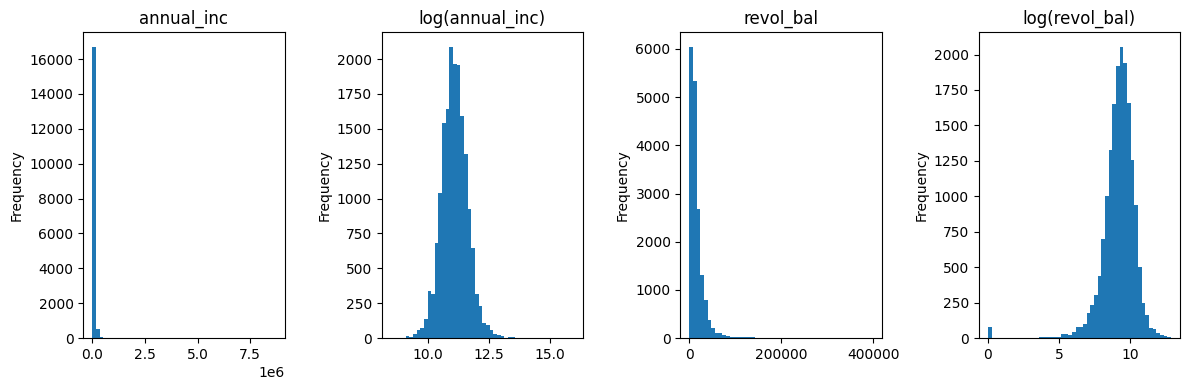

In [ ]:
plt.figure(figsize=(12,4))
plt.subplot(1,4,1)
df_clean['annual_inc'].plot(kind='hist', bins=50)
plt.title('annual_inc')
plt.subplot(1,4,2)
df_clean['annual_inc_log'].plot(kind='hist', bins=50)
plt.title('log(annual_inc)')
plt.subplot(1,4,3)
df_clean['revol_bal'].plot(kind='hist', bins=50)
plt.title('revol_bal')
plt.subplot(1,4,4)
df_clean['revol_bal_log'].plot(kind='hist', bins=50)
plt.title('log(revol_bal)')
plt.tight_layout()
plt.show()

Los conteos por IQR coinciden con la fase 1 (annual_inc 838 = 4.85%, revol_bal 1,004 = 5.82%, open_acc 605 = 3.5%, entre otros). La única diferencia es revol_util, que pasa de 2 atípicos a 0 porque el recorte a 100 los eliminó.

**Decisión: no se elimina ninguna fila (0 filas eliminadas).** Estos valores son atípicos legítimos (personas con ingresos o saldos altos) y no errores de captura. Eliminarlos sacaría del modelo a clientes reales. En cambio, se reduce su influencia con una transformación logarítmica (log1p):
*   **annual_inc**: la asimetría (skew) baja de 64.37 a 0.18, prácticamente simétrica.
*   **revol_bal**: el skew pasa de 6.02 a -2.55. El valor negativo se debe a las 77 personas con saldo rotativo igual a 0, que quedan aisladas a la izquierda. La cola larga de valores altos, que era el problema original, queda controlada.

Después del log se aplica StandardScaler (ver Imputation and scaling).

## Cleaning summary

| Tratamiento | Conteo fase 1 | Acción en fase 2 | Filas afectadas |
|---|---|---|---|
| Duplicados | 0 | Ninguna | 0 |
| Formato de term (espacio inicial) | Toda la columna | strip() | 17,264 |
| Tipo de term | Texto | Entero (36 / 60) | 17,264 |
| Tipo de issue_d | Texto | Fecha (datetime) | 17,264 (0 errores) |
| annual_inc = 0 | 5 | Convertido a nulo e imputado con la mediana del train | 5 |
| revol_util > 100 | 63 | Recorte (clip) a 100 | 63 |
| Nulos emp_length / mort_acc / revol_util / dti / annual_inc | 1,040 / 647 / 7 / 5 / (5) | Imputación con la mediana del train | 1,704 valores |
| Atípicos (IQR) | p. ej. annual_inc 838, revol_bal 1,004 | Se conservan, con log en annual_inc y revol_bal | 0 eliminadas |

**Resultado: se conservan las 17,264 filas.** Ningún tratamiento eliminó registros, así que el tamaño final coincide con el reportado en la fase 1.

# Exploratory Data Analysis

Se ejecuta el análisis univariado, bivariado y multivariado propuesto en la fase 1, ahora sobre los datos limpios y ampliado a todas las variables. Cada nivel termina con los hallazgos y con lo que implican para la selección de variables y de modelos.

## Univariate

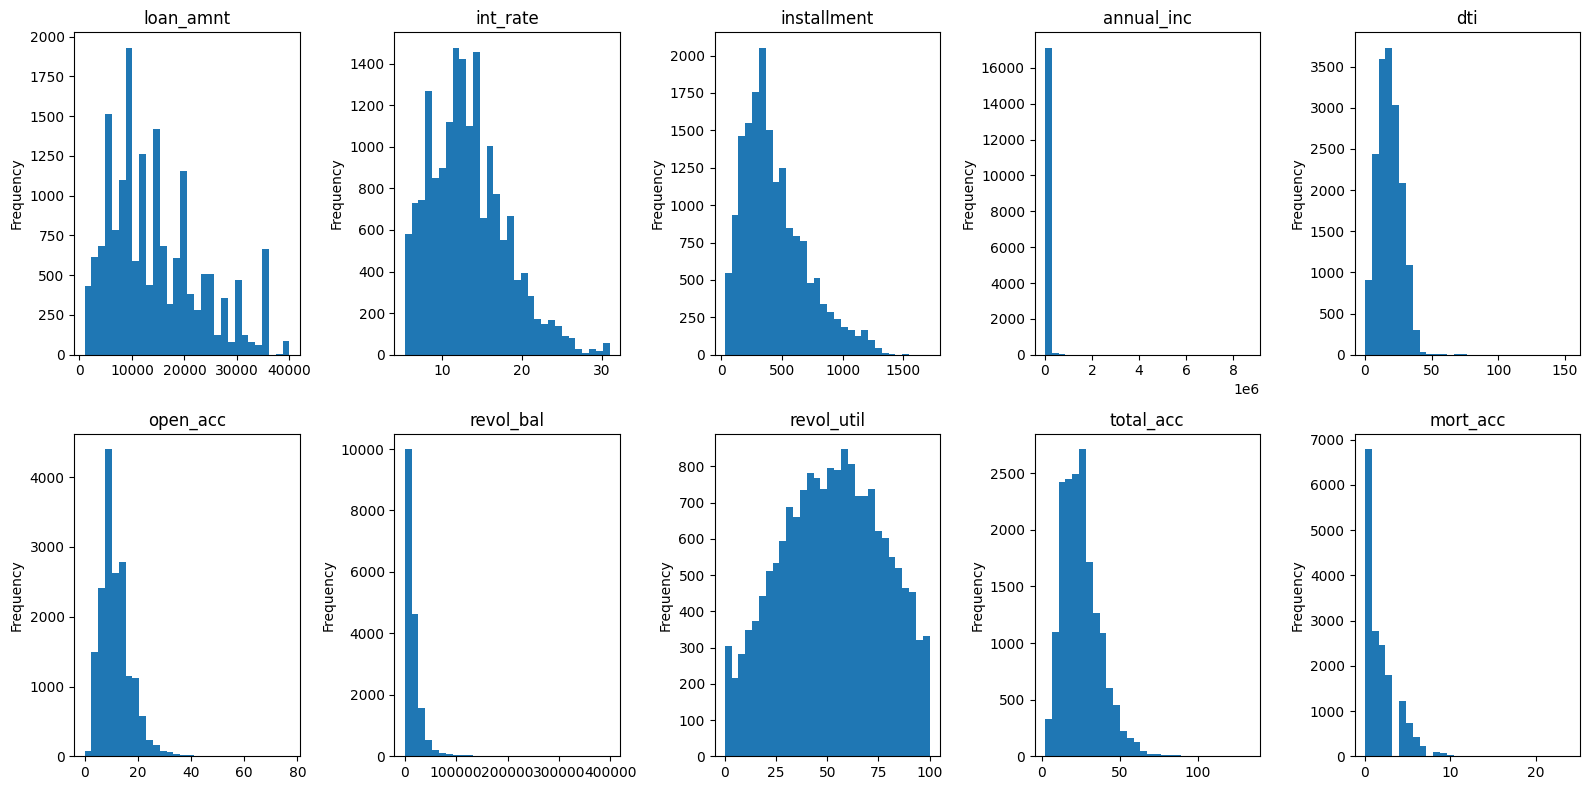

In [ ]:
plt.figure(figsize=(16,8))
for i, col in enumerate(numerical):
    plt.subplot(2,5,i+1)
    df_clean[col].plot(kind='hist', bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()

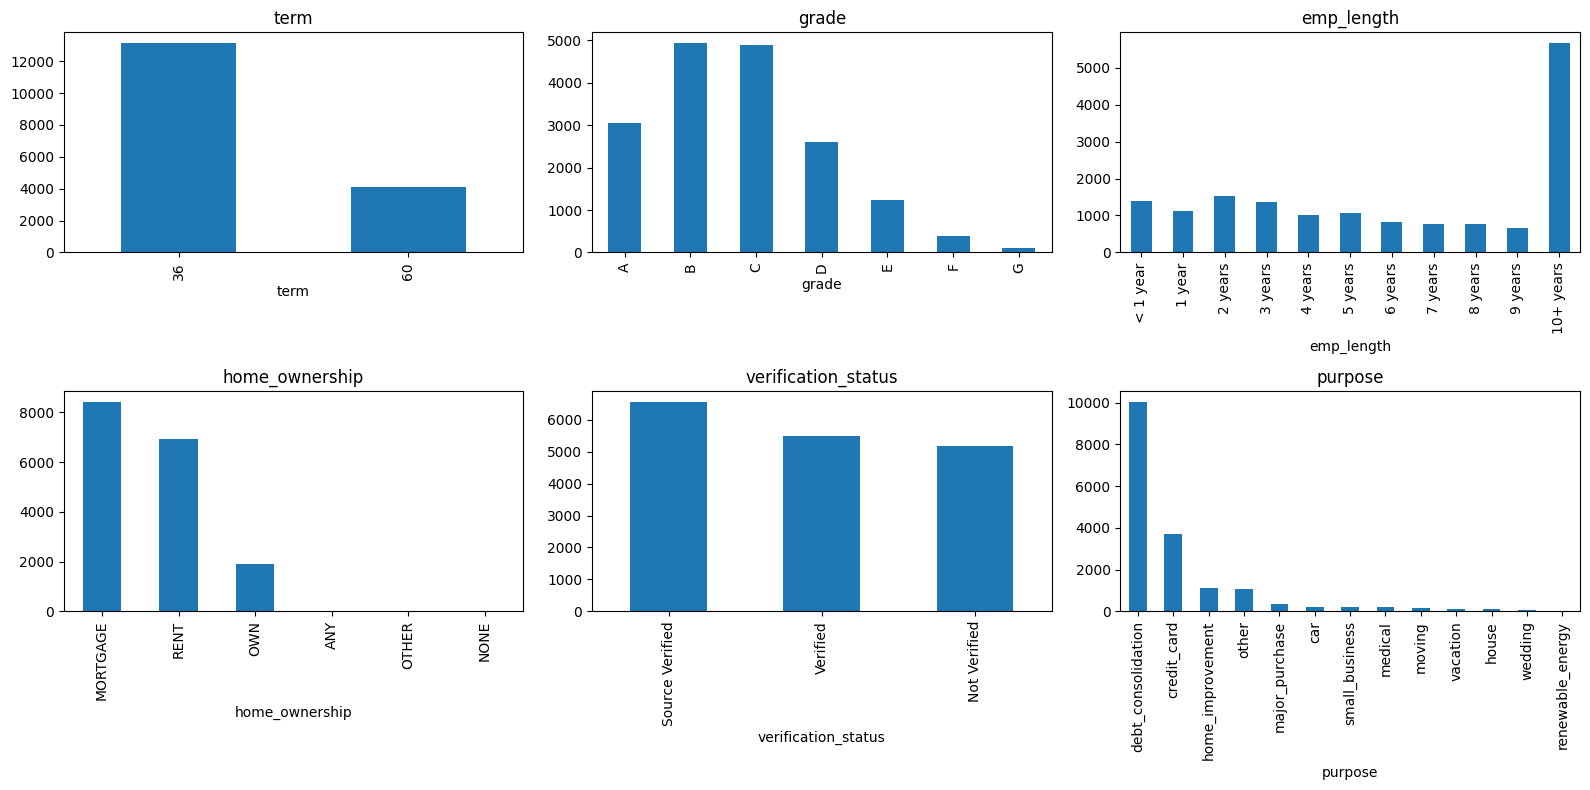

In [ ]:
cat_eda = ['term', 'grade', 'emp_length', 'home_ownership', 'verification_status', 'purpose']
orden = {'term': [36, 60],
         'grade': ['A', 'B', 'C', 'D', 'E', 'F', 'G'],
         'emp_length': ['< 1 year', '1 year', '2 years', '3 years', '4 years', '5 years',
                        '6 years', '7 years', '8 years', '9 years', '10+ years']}

plt.figure(figsize=(16,8))
for i, col in enumerate(cat_eda):
    plt.subplot(2,3,i+1)
    conteo = df_clean[col].value_counts()
    if col in orden:
        conteo = conteo.reindex(orden[col])
    conteo.plot(kind='bar')
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
for col in ['term', 'home_ownership', 'purpose', 'application_type']:
    print(df_clean[col].value_counts(normalize=True).round(4) * 100)
    print()

term
36    76.21
60    23.79
Name: proportion, dtype: float64

home_ownership
MORTGAGE    48.86
RENT        40.14
OWN         10.96
ANY          0.02
OTHER        0.01
NONE         0.01
Name: proportion, dtype: float64

purpose
debt_consolidation    58.26
credit_card           21.44
home_improvement       6.41
other                  6.11
major_purchase         2.13
car                    1.19
small_business         1.09
medical                1.09
moving                 0.76
vacation               0.74
house                  0.52
wedding                0.21
renewable_energy       0.05
Name: proportion, dtype: float64

application_type
Individual    98.23
Joint App      1.77
Name: proportion, dtype: float64



**Hallazgos:**
*   Las variables monetarias (loan_amnt, annual_inc, revol_bal) y de conteo (open_acc, total_acc, mort_acc) tienen sesgo a la derecha. Esto confirma la necesidad del log y del escalado.
*   **term** está desbalanceada: 76.2% a 36 meses y 23.8% a 60 meses.
*   **grade** se concentra en B y C, y G es muy escasa (116 préstamos).
*   **home_ownership** tiene tres categorías con muy pocos casos: ANY (4), OTHER (2) y NONE (1), que suman 7 filas (0.04%).
*   **purpose** está dominado por debt_consolidation (58.3%) y credit_card (21.4%). Cinco categorías tienen menos del 1% (moving, vacation, house, wedding y renewable_energy).
*   **application_type** es Individual en el 98.2% de los casos.

**Implicación para el modelado:** las categorías con muy pocos casos se agruparán para que no aparezcan columnas casi vacías en el train, que no permiten aprender un patrón confiable.

## Bivariate

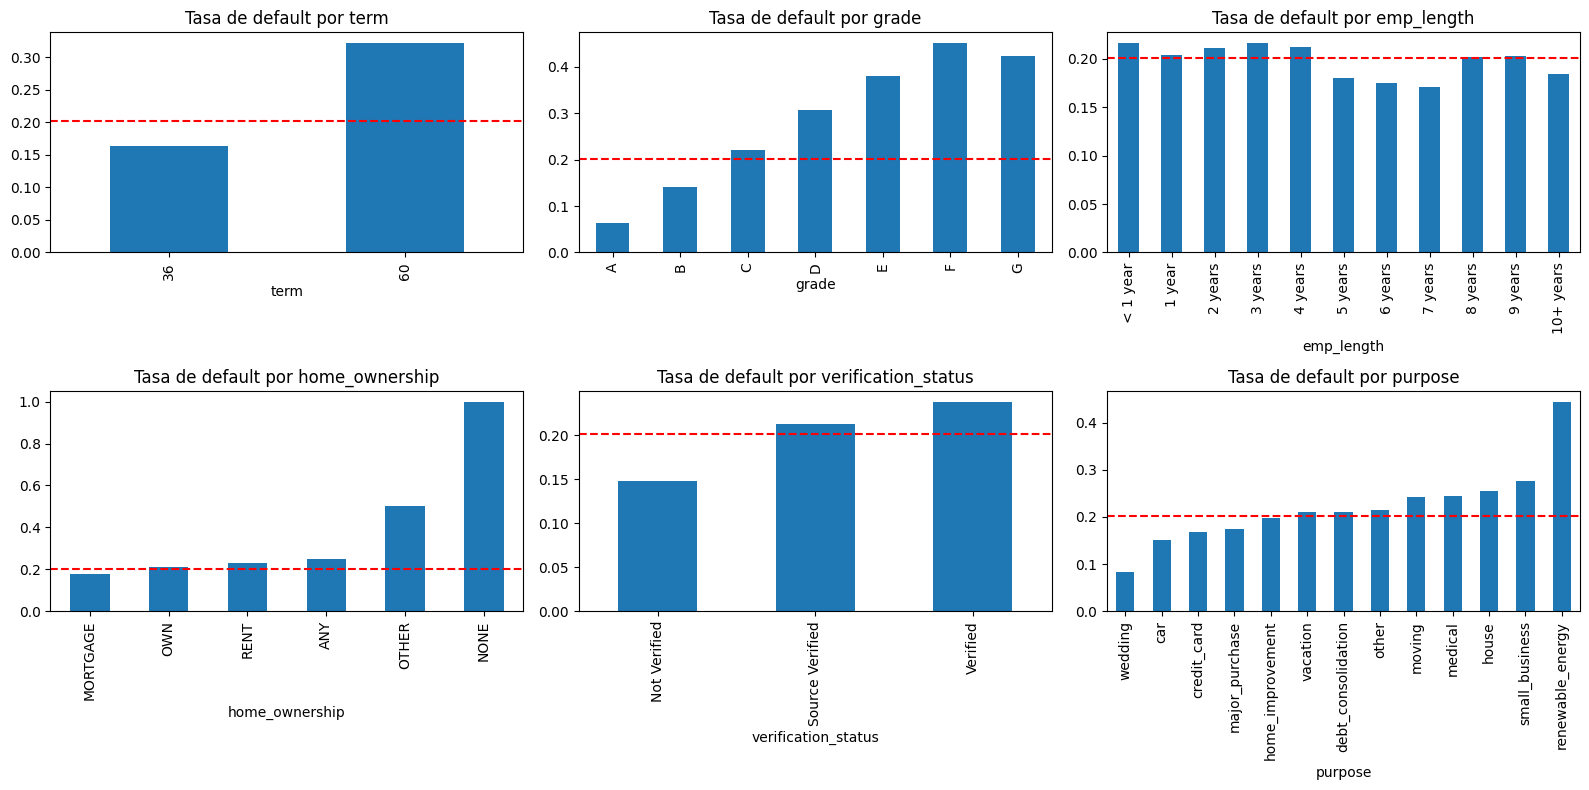

In [ ]:
plt.figure(figsize=(16,8))
for i, col in enumerate(cat_eda):
    plt.subplot(2,3,i+1)
    tasa = df_clean.groupby(col)['default'].mean()
    if col in orden:
        tasa = tasa.reindex(orden[col])
    else:
        tasa = tasa.sort_values()
    tasa.plot(kind='bar')
    plt.axhline(df_clean['default'].mean(), color='red', linestyle='--')
    plt.title('Tasa de default por ' + col)
plt.tight_layout()
plt.show()

             mean  count
issue_year              
2007        0.143      7
2008        0.294     17
2009        0.098     61
2010        0.106    142
2011        0.149    315
2012        0.167    738
2013        0.156   1831
2014        0.186   2935
2015        0.204   4908
2016        0.240   3583
2017        0.234   2094
2018        0.150    633


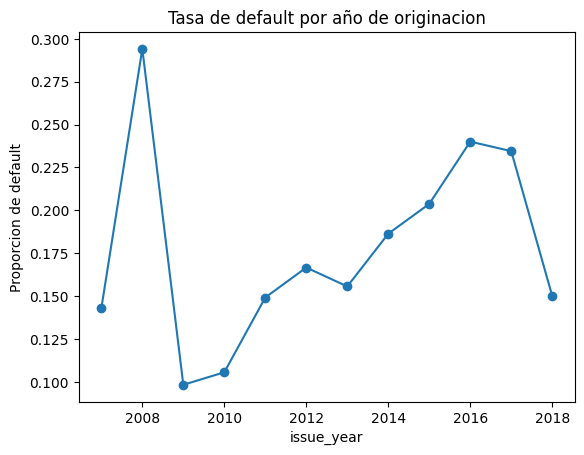

In [ ]:
df_clean['issue_year'] = df_clean['issue_d'].dt.year
print(df_clean.groupby('issue_year')['default'].agg(['mean', 'count']).round(3))
df_clean.groupby('issue_year')['default'].mean().plot(kind='line', marker='o')
plt.title('Tasa de default por año de originacion')
plt.ylabel('Proporcion de default')
plt.show()

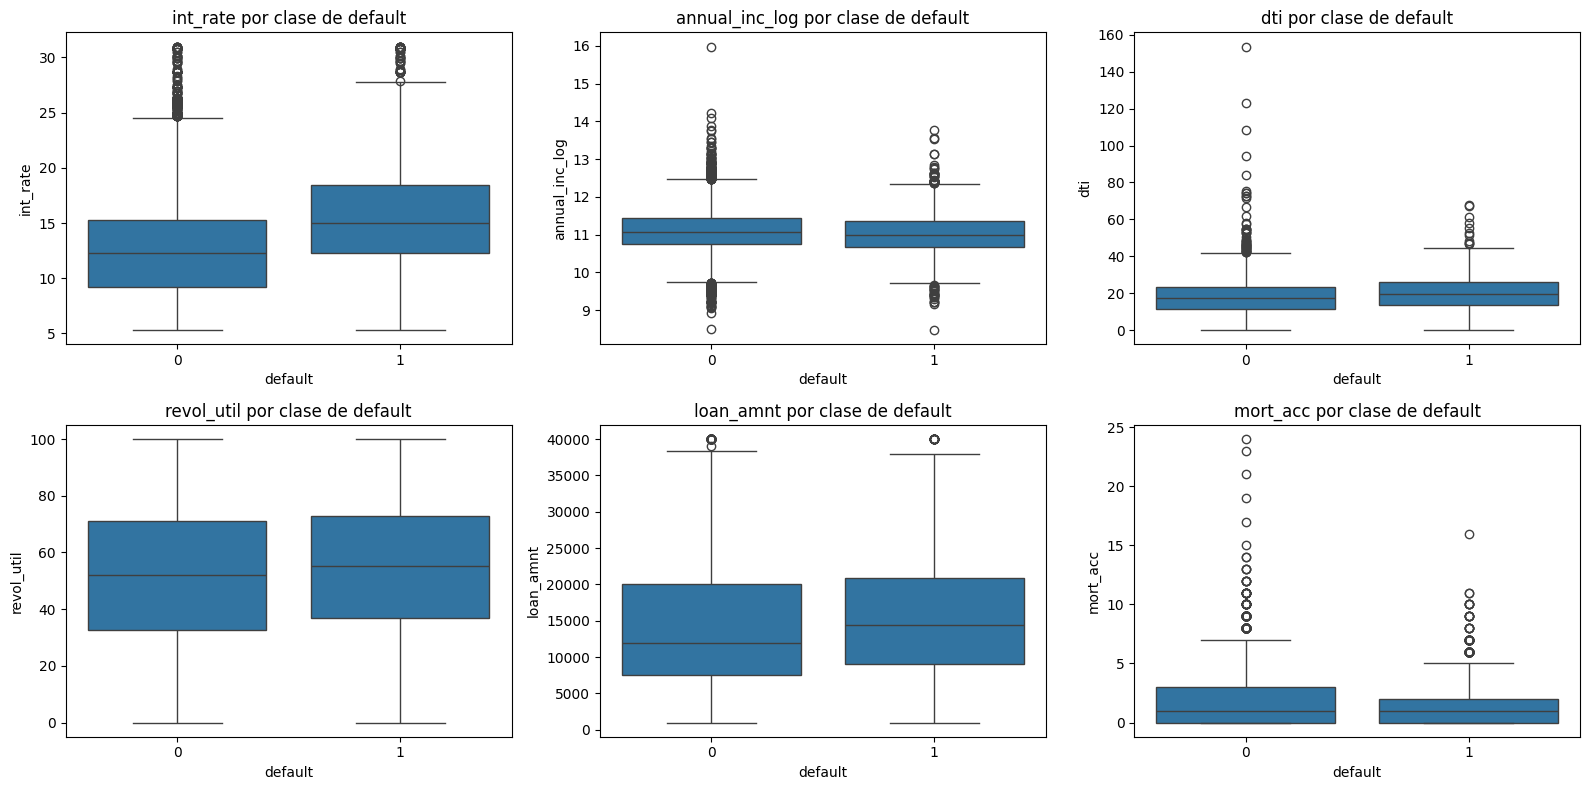

In [ ]:
plt.figure(figsize=(16,8))
for i, col in enumerate(['int_rate', 'annual_inc_log', 'dti', 'revol_util', 'loan_amnt', 'mort_acc']):
    plt.subplot(2,3,i+1)
    sns.boxplot(data=df_clean, x='default', y=col)
    plt.title(col + ' por clase de default')
plt.tight_layout()
plt.show()

In [ ]:
print(df_clean.groupby('default')[numerical].median().T.round(2))

default             0         1
loan_amnt    12000.00  14350.00
int_rate        12.29     14.99
installment    370.86    406.24
annual_inc   65000.00  60000.00
dti             17.27     19.80
open_acc        11.00     11.00
revol_bal    11245.00  11267.00
revol_util      51.90     55.25
total_acc       23.00     23.00
mort_acc         1.00      1.00


**Hallazgos (la línea roja es la tasa promedio de default, 20.1%):**
*   **grade** es la señal más fuerte: el default sube de forma casi monótona, de 6.4% en A a 45.2% en F. G (42.2%) rompe levemente la tendencia, pero solo tiene 116 préstamos.
*   **term**: los préstamos a 60 meses incumplen el doble que los de 36 (32.2% frente a 16.4%).
*   **verification_status** confirma el hallazgo contraintuitivo de la fase 1: Not Verified 14.8%, Source Verified 21.3% y Verified 23.8%. La verificación se aplicaba con más rigor a quienes la plataforma ya percibía como riesgosos, así que funciona como una señal de riesgo.
*   **home_ownership**: MORTGAGE tiene menor riesgo (17.7%) que OWN (21.1%) y RENT (22.8%). Las tasas extremas de NONE/OTHER/ANY se deben a que son solo 7 casos.
*   **purpose**: small_business (27.7%) es el propósito más riesgoso con un tamaño de muestra razonable, y credit_card (16.9%) uno de los menos riesgosos.
*   **emp_length** tiene una relación débil y no monótona (entre 17.1% y 21.6%): aporta poca información por sí sola.
*   **Numéricas**: los préstamos en default tienen una tasa de interés mediana mayor (14.99% frente a 12.29%), un dti mayor (19.80 frente a 17.27), montos mayores (14,350 frente a 12,000) e ingresos menores (60,000 frente a 65,000). open_acc, total_acc y mort_acc tienen la misma mediana en ambas clases.
*   **issue_d**: el default sube de 9.8% (2009) a 24.0% (2016) y cae a 15.0% en 2018. Esa caída no significa que los préstamos de 2018 fueran mejores. Es **sesgo de supervivencia**: muchos préstamos de 2018 seguían vigentes cuando se publicaron los datos y quedaron excluidos (estado Current), y los que ya habían terminado son sobre todo los que se pagaron anticipadamente. **Por esto issue_d no se usa como predictor.**

**Implicación:** grade/sub_grade, int_rate y term deben estar en el modelo, verification_status se conserva como señal real, y la relación entre las variables y el riesgo es en general monótona.

## Multivariate

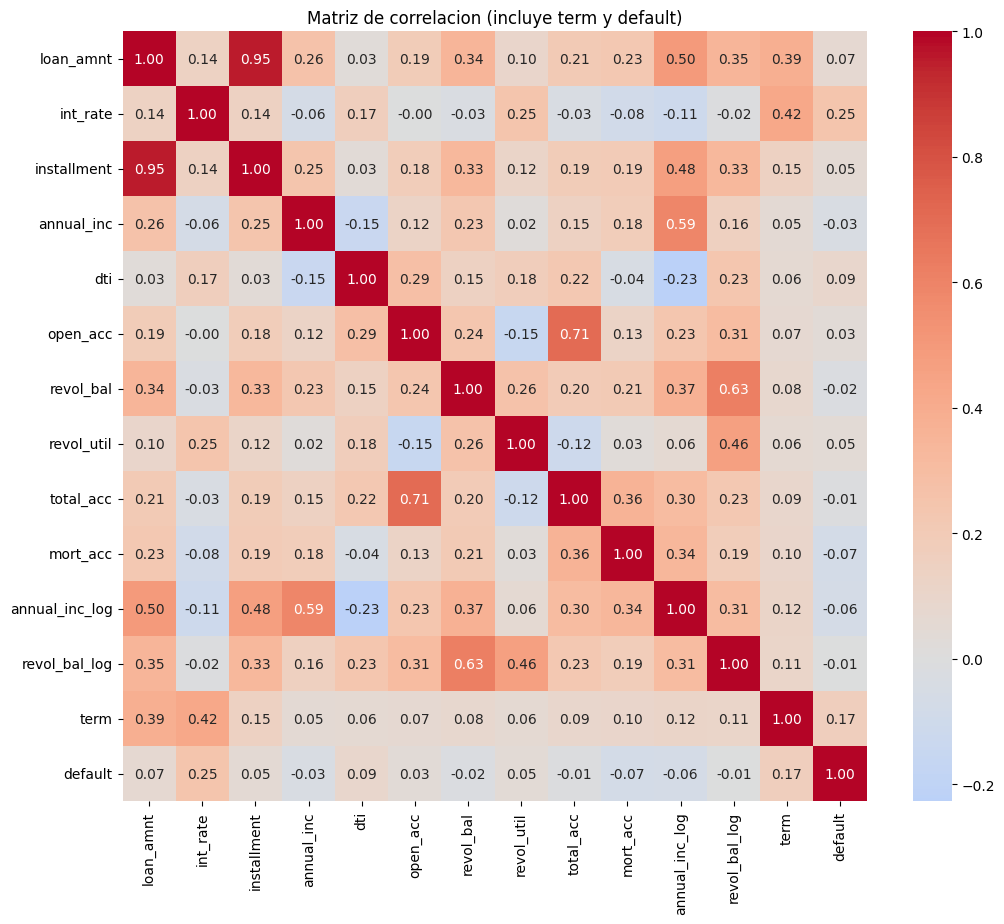

int_rate          0.251
term              0.168
dti               0.094
loan_amnt         0.068
installment       0.054
revol_util        0.045
open_acc          0.032
revol_bal_log    -0.005
total_acc        -0.010
revol_bal        -0.016
annual_inc       -0.034
annual_inc_log   -0.061
mort_acc         -0.075
Name: default, dtype: float64


In [ ]:
corr_cols = numerical + ['annual_inc_log', 'revol_bal_log', 'term', 'default']
corr = df_clean[corr_cols].corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlacion (incluye term y default)')
plt.show()
print(corr['default'].drop('default').sort_values(ascending=False).round(3))

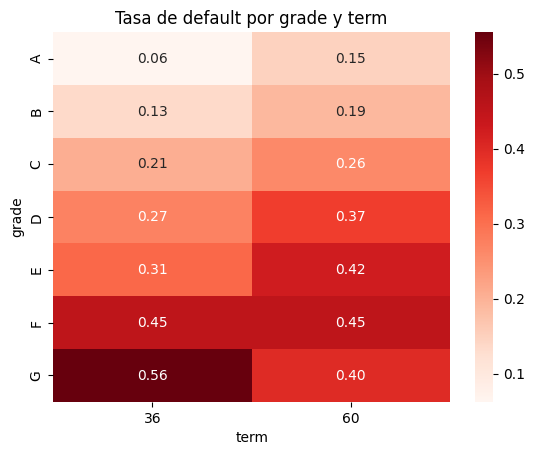

In [ ]:
tabla = df_clean.pivot_table(index='grade', columns='term', values='default', aggfunc='mean')
sns.heatmap(tabla, annot=True, fmt='.2f', cmap='Reds')
plt.title('Tasa de default por grade y term')
plt.show()

**Hallazgos:**
*   Ninguna variable numérica tiene una correlación fuerte con default. La más alta es int_rate (0.25), seguida de term (0.17) y dti (0.09). **Ninguna variable separa las clases por sí sola**, así que el modelo debe combinar varias señales débiles. Esto anticipa un desempeño moderado: un AUC cercano a 0.70 es realista para este problema.
*   **Redundancias** confirmadas: loan_amnt e installment (0.95), open_acc y total_acc (0.71). Más adelante se verá que grade, sub_grade e int_rate también están casi perfectamente correlacionadas (0.95 a 0.98).
*   **grade × term**: dentro de casi todos los grades, el plazo de 60 meses tiene más default que el de 36 (A: 15% frente a 6%, D: 37% frente a 27%, E: 42% frente a 31%). Esto indica que **term aporta información adicional a la de grade**, así que se conservan ambas. En F y G la tendencia se invierte, pero hay muy pocos préstamos (F tiene 84 a 36 meses y G solo 18).

**Implicación para el modelo:** como hay redundancias, conviene eliminar las variables duplicadas y probar la reducción de dimensionalidad. Como las señales son débiles y combinadas, se justifica comparar un modelo lineal con modelos de árboles que capturen interacciones.

# Feature Engineering

A partir de los hallazgos del EDA se construye la matriz de variables X que recibirán los modelos: se crea una variable nueva, se codifican las variables categóricas y se eliminan las redundantes. Se trabaja sobre una copia (df_fe).

## New features and redundancy

In [ ]:
df_fe = df_clean.copy()
df_fe['loan_to_income'] = df_fe['loan_amnt'] / df_fe['annual_inc']
df_fe['loan_to_income_log'] = np.log1p(df_fe['loan_to_income'])

print(df_fe.groupby('default')['loan_to_income'].median())
print('Correlacion con default:', round(df_fe['loan_to_income_log'].corr(df_fe['default']), 3))

default
0    0.189394
1    0.234852
Name: loan_to_income, dtype: float64
Correlacion con default: 0.129


**loan_to_income = loan_amnt / annual_inc** mide qué tan grande es el préstamo frente a la capacidad de pago del solicitante. Ni el monto ni el ingreso por separado capturan esto: un préstamo de 20,000 es muy distinto para alguien que gana 30,000 que para alguien que gana 200,000. Los préstamos en default tienen una razón mediana mayor (0.235 frente a 0.189), y su versión logarítmica tiene una correlación con default de 0.129, más alta que la de loan_amnt (0.068) o annual_inc_log (−0.061) por separado. Se usa su versión logarítmica (loan_to_income_log), porque hereda el sesgo de annual_inc. Los 5 préstamos con annual_inc nulo quedan con loan_to_income nulo y se imputan como el resto.

## Ordinal encoding

In [ ]:
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
df_fe['grade'] = df_fe['grade'].map(grade_map)

df_fe['sub_grade'] = df_fe['sub_grade'].str[0].map(grade_map) * 5 - 5 + df_fe['sub_grade'].str[1].astype(int)

emp_map = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5,
           '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10}
df_fe['emp_length'] = df_fe['emp_length'].map(emp_map)

print(df_fe[['grade', 'sub_grade', 'emp_length']].describe().round(2))
print(df_fe[['grade', 'sub_grade', 'int_rate']].corr().round(3))

          grade  sub_grade  emp_length
count  17264.00   17264.00    16224.00
mean       2.75      11.71        5.98
std        1.30       6.46        3.69
min        1.00       1.00        0.00
25%        2.00       7.00        3.00
50%        3.00      11.00        6.00
75%        4.00      16.00       10.00
max        7.00      35.00       10.00
           grade  sub_grade  int_rate
grade      1.000      0.976     0.952
sub_grade  0.976      1.000     0.975
int_rate   0.952      0.975     1.000


*   **grade**: A=1 ... G=7.
*   **sub_grade**: A1=1 ... G5=35, que conserva el orden fino dentro de cada grade.
*   **emp_length**: '< 1 year'=0 ... '10+ years'=10. Los 1,040 nulos se mantienen como NaN para imputarlos después.

Codificarlas como ordinales en lugar de one-hot conserva su orden natural (como se propuso en la fase 1) y evita crear 35 columnas para sub_grade. La matriz de correlación muestra que **grade y sub_grade tienen r = 0.976**, así que **se elimina grade**: toda su información ya está en sub_grade. int_rate también está muy correlacionada con sub_grade (0.975), pero se conserva porque la tasa cambió en el tiempo para un mismo subgrado y aporta matices de precio. La regularización de la regresión logística y los modelos de árboles manejan bien esta redundancia.

## Grouping rare categories and one-hot encoding

In [ ]:
df_fe['home_ownership'] = df_fe['home_ownership'].replace({'NONE': 'OTHER', 'ANY': 'OTHER'})

frecuencia = df_fe['purpose'].value_counts(normalize=True)
raras = frecuencia[frecuencia < 0.01].index.tolist()
print('Categorias de purpose agrupadas en other:', raras)
df_fe['purpose'] = df_fe['purpose'].replace(raras, 'other')
purpose_validos = sorted(df_fe['purpose'].unique().tolist())

print(df_fe['home_ownership'].value_counts())
print(df_fe['purpose'].value_counts())

Categorias de purpose agrupadas en other: ['moving', 'vacation', 'house', 'wedding', 'renewable_energy']
home_ownership
MORTGAGE    8436
RENT        6929
OWN         1892
OTHER          7
Name: count, dtype: int64
purpose
debt_consolidation    10058
credit_card            3701
other                  1449
home_improvement       1107
major_purchase          368
car                     205
small_business          188
medical                 188
Name: count, dtype: int64


In [ ]:
nominales = ['home_ownership', 'verification_status', 'purpose', 'application_type']
df_fe = pd.get_dummies(df_fe, columns=nominales, drop_first=True, dtype=int)
print(df_fe.shape)

(17264, 35)


*   **home_ownership**: ANY (4) y NONE (1) se agrupan en OTHER, que queda con 7 casos.
*   **purpose**: las 5 categorías con menos del 1% (moving, vacation, house, wedding y renewable_energy, 395 préstamos en total) se agrupan en 'other', que pasa de 1,054 a 1,449 casos.
*   **One-hot encoding** de home_ownership, verification_status, purpose y application_type, con drop_first=True para evitar la colinealidad perfecta entre las dummies. Las categorías de referencia son MORTGAGE, Not Verified, car e Individual.

## Final feature set

In [ ]:
eliminar = ['loan_status', 'default', 'issue_d', 'issue_year', 'installment', 'grade',
            'annual_inc', 'revol_bal', 'loan_to_income']
X = df_fe.drop(columns=eliminar)
y = df_fe['default']

print('Variables finales:', X.shape[1])
print(X.columns.tolist())

Variables finales: 26
['loan_amnt', 'int_rate', 'dti', 'open_acc', 'revol_util', 'total_acc', 'mort_acc', 'term', 'sub_grade', 'emp_length', 'annual_inc_log', 'revol_bal_log', 'loan_to_income_log', 'home_ownership_OTHER', 'home_ownership_OWN', 'home_ownership_RENT', 'verification_status_Source Verified', 'verification_status_Verified', 'purpose_credit_card', 'purpose_debt_consolidation', 'purpose_home_improvement', 'purpose_major_purchase', 'purpose_medical', 'purpose_other', 'purpose_small_business', 'application_type_Joint App']


**Conjunto final: 26 variables predictoras.**

Se excluyen:
*   **loan_status y default**: son el target.
*   **issue_d e issue_year**: no son útiles para predecir préstamos futuros y tienen sesgo de supervivencia (ver EDA bivariado).
*   **installment**: redundante con loan_amnt (r = 0.95).
*   **grade**: redundante con sub_grade (r = 0.976).
*   **annual_inc, revol_bal y loan_to_income**: se reemplazan por sus versiones logarítmicas.

## Train/Test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Proporcion de default en train:', round(y_train.mean(), 4))
print('Proporcion de default en test:', round(y_test.mean(), 4))

Train: (13811, 26)  Test: (3453, 26)
Proporcion de default en train: 0.2013
Proporcion de default en test: 0.2013


Partición **80/20 estratificada** (random_state=42), como se propuso: 13,811 préstamos de entrenamiento y 3,453 de prueba, ambos con exactamente 20.13% de default. El conjunto de prueba se reserva hasta la evaluación final y no se usa para tomar ninguna decisión de modelado.

## Imputation and scaling

In [ ]:
medianas = X_train.median()
print('Medianas usadas para imputar:')
print(medianas[X_train.columns[X_train.isnull().any()]])

X_train_imp = X_train.fillna(medianas)
X_test_imp = X_test.fillna(medianas)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print('Nulos restantes en train:', X_train_imp.isnull().sum().sum(), ' en test:', X_test_imp.isnull().sum().sum())

Medianas usadas para imputar:
dti                   17.610000
revol_util            52.500000
mort_acc               1.000000
emp_length             6.000000
annual_inc_log        11.082158
loan_to_income_log     0.182322
dtype: float64
Nulos restantes en train: 0  en test: 0


*   **Imputación**: las medianas se calculan **solo con X_train** y se aplican a train y test. Por ejemplo, la mediana de emp_length es 6 años, la de mort_acc es 1 y la de dti es 17.61.
*   **Escalado**: StandardScaler se ajusta (fit) solo con train y luego transforma train y test. Deja las variables con media 0 y desviación 1, que es lo que necesitan la regresión logística, PCA y LDA.

Después de este paso no queda ningún nulo en train ni en test.

# Feature Reduction

**¿Por qué reducir?** El one-hot encoding llevó el problema a 26 variables, y el EDA mostró redundancias (sub_grade/int_rate, open_acc/total_acc). La reducción de dimensionalidad puede eliminar esa multicolinealidad, simplificar los modelos y reducir el sobreajuste. Siguiendo lo visto en clase, se aplica **PCA** (no supervisado, maximiza la varianza) y, como complemento, **LDA** (supervisado, maximiza la separación entre clases). Su impacto real en el desempeño se evalúa en Modeling Approach.

## PCA

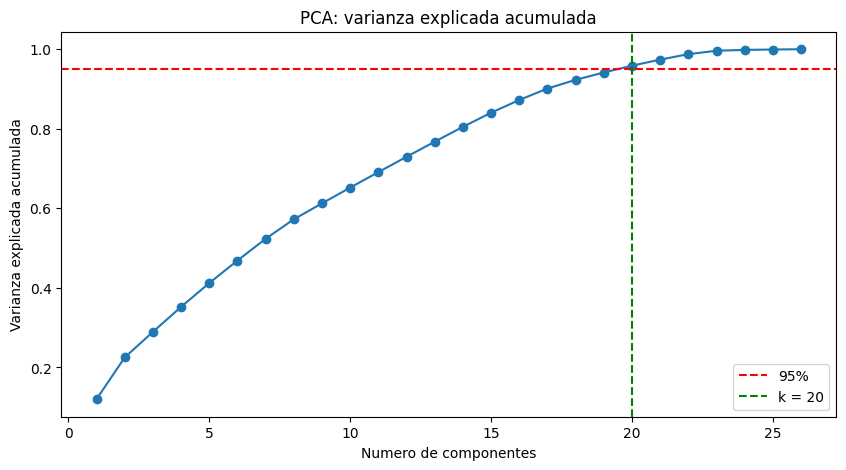

Variables originales: 26
Componentes seleccionados (95%): 20


In [ ]:
pca_full = PCA()
pca_full.fit(X_train_scaled)

varianza_acumulada = np.cumsum(pca_full.explained_variance_ratio_)
k = np.argmax(varianza_acumulada >= 0.95) + 1

plt.figure(figsize=(10,5))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o')
plt.axhline(0.95, color='red', linestyle='--', label='95%')
plt.axvline(k, color='green', linestyle='--', label='k = ' + str(k))
plt.xlabel('Numero de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA: varianza explicada acumulada')
plt.legend()
plt.show()

print('Variables originales:', X_train_scaled.shape[1])
print('Componentes seleccionados (95%):', k)

In [ ]:
pca = PCA(n_components=k)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(pca.explained_variance_ratio_.round(4))
print('Varianza explicada total:', round(sum(pca.explained_variance_ratio_), 4))

[0.1202 0.1049 0.0643 0.0629 0.0598 0.0567 0.0547 0.0491 0.04   0.0396
 0.039  0.0384 0.0381 0.0372 0.0355 0.032  0.0288 0.0219 0.0184 0.0171]
Varianza explicada total: 0.9586


In [ ]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=['PC1', 'PC2', 'PC3'])
for pc in ['PC1', 'PC2', 'PC3']:
    print(pc, cargas[pc].abs().sort_values(ascending=False).head(5).round(3).to_dict())

PC1 {'loan_amnt': 0.39, 'term': 0.33, 'sub_grade': 0.305, 'int_rate': 0.302, 'revol_bal_log': 0.287}
PC2 {'sub_grade': 0.396, 'int_rate': 0.395, 'annual_inc_log': 0.366, 'total_acc': 0.323, 'mort_acc': 0.313}
PC3 {'purpose_debt_consolidation': 0.451, 'dti': 0.319, 'purpose_home_improvement': 0.314, 'purpose_other': 0.303, 'int_rate': 0.266}


*   **Número de componentes:** con el umbral del 95% visto en clase se necesitan **k = 20 componentes**, que explican el **95.86%** de la varianza. La reducción es pequeña: de 26 a 20 variables (23%).
*   La varianza está muy repartida: PC1 explica solo el 12.0% y PC2 el 10.5%. Esto confirma lo que mostró la matriz de correlación: salvo unos pocos pares, las variables son bastante independientes entre sí, así que no hay mucha redundancia que comprimir.
*   **Interpretación de los componentes:** PC1 agrupa loan_amnt, term, sub_grade, int_rate y revol_bal_log, es decir, el "tamaño y costo del préstamo". PC2 combina sub_grade, int_rate, annual_inc_log, total_acc y mort_acc, que describen el "perfil financiero del solicitante". PC3 está dominado por el propósito del préstamo y el dti.

PCA no usa la etiqueta, así que maximizar la varianza no garantiza conservar la información que separa default de no default. Esto se verifica en la siguiente sección.

## LDA

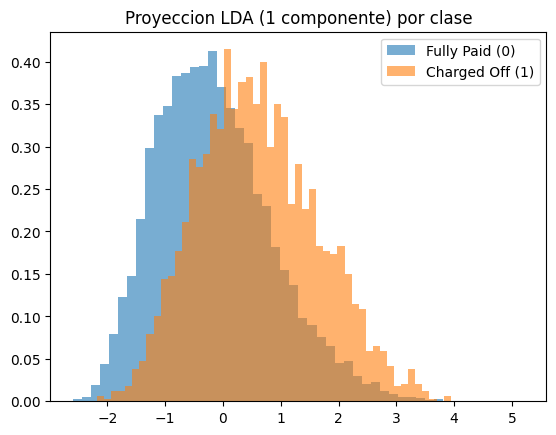

In [ ]:
lda = LinearDiscriminantAnalysis(n_components=1)
X_train_lda = lda.fit_transform(X_train_scaled, y_train)

plt.hist(X_train_lda[y_train == 0], bins=50, alpha=0.6, label='Fully Paid (0)', density=True)
plt.hist(X_train_lda[y_train == 1], bins=50, alpha=0.6, label='Charged Off (1)', density=True)
plt.title('Proyeccion LDA (1 componente) por clase')
plt.legend()
plt.show()

Como el problema es binario, LDA produce como máximo **1 componente** (número de clases − 1). El histograma muestra que la proyección separa parcialmente las clases: los préstamos en default se desplazan hacia la derecha, pero las distribuciones se solapan bastante. Esto es coherente con el EDA, donde ninguna variable separaba las clases con claridad.

# Modeling Approach

Se implementan los **tres modelos propuestos en la fase 1**:
*   **Logistic Regression**: línea base interpretable. Sus coeficientes muestran la dirección y magnitud del efecto de cada variable.
*   **Random Forest**: ensamble de árboles que captura relaciones no lineales e interacciones (por ejemplo, grade × term) y es robusto frente a atípicos.
*   **XGBoost**: ensamble de boosting, estándar en scoring crediticio sobre datos tabulares.

**Métricas:** Accuracy, Precision, Recall, F1-score y AUC-ROC, más la matriz de confusión. Por el desbalance (80/20), el criterio principal es el **F1 de la clase default** (equilibrio entre detectar incumplimientos y no generar demasiadas falsas alarmas), complementado con el **AUC**, que mide la capacidad de ordenar a los clientes por riesgo sin depender del umbral.

## Cross-validation function

In [ ]:
def evaluar_cv(modelo, X, y, reduccion, usar_smote):
    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    resultados = []
    for train_idx, val_idx in kf.split(X, y):
        X_tr, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]

        med = X_tr.median()
        X_tr = X_tr.fillna(med)
        X_val = X_val.fillna(med)

        sc = StandardScaler()
        X_tr = sc.fit_transform(X_tr)
        X_val = sc.transform(X_val)

        if reduccion == 'PCA':
            p = PCA(n_components=k)
            X_tr = p.fit_transform(X_tr)
            X_val = p.transform(X_val)
        if reduccion == 'LDA':
            l = LinearDiscriminantAnalysis(n_components=1)
            X_tr = l.fit_transform(X_tr, y_tr)
            X_val = l.transform(X_val)

        if usar_smote:
            smote = SMOTE(random_state=42)
            X_tr, y_tr = smote.fit_resample(X_tr, y_tr)

        modelo.fit(X_tr, y_tr)
        pred = modelo.predict(X_val)
        prob = modelo.predict_proba(X_val)[:, 1]
        resultados.append([accuracy_score(y_val, pred), precision_score(y_val, pred, zero_division=0),
                           recall_score(y_val, pred), f1_score(y_val, pred), roc_auc_score(y_val, prob)])

    resultados = np.array(resultados)
    return resultados.mean(axis=0), resultados.std(axis=0)

Esta función implementa la **validación cruzada estratificada de 5 folds** propuesta en la fase 1 (StratifiedKFold mantiene el 20% de default en cada fold). En cada iteración, **todo el preprocesamiento se ajusta solo con los 4 folds de entrenamiento**: medianas, escalado, PCA o LDA y SMOTE. Después se evalúa en el fold de validación, que nunca se toca. Así se evita la fuga de datos. En particular, SMOTE nunca genera datos sintéticos en el fold de validación: se evalúa siempre sobre préstamos reales con su proporción real de default. La función devuelve el promedio y la desviación estándar de las 5 evaluaciones.

## Impact of feature reduction and class balancing

In [ ]:
modelos = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss'),
}

filas = []
for nombre, modelo in modelos.items():
    for reduccion in ['Ninguna', 'PCA', 'LDA']:
        for usar_smote in [False, True]:
            media, desv = evaluar_cv(modelo, X_train, y_train, reduccion, usar_smote)
            filas.append([nombre, reduccion, usar_smote] + list(media.round(4)) + [desv[4].round(4)])

comparacion = pd.DataFrame(filas, columns=['Modelo', 'Reduccion', 'SMOTE', 'Accuracy', 'Precision',
                                           'Recall', 'F1', 'AUC', 'AUC std'])
comparacion

,Modelo,Reduccion,SMOTE,Accuracy,Precision,Recall,F1,AUC,AUC std
0,Logistic Regression,Ninguna,False,0.7973,0.4755,0.0698,0.1213,0.7001,0.0096
1,Logistic Regression,Ninguna,True,0.6551,0.3176,0.6209,0.4202,0.6994,0.0090
2,Logistic Regression,PCA,False,0.7978,0.4850,0.0705,0.1228,0.6999,0.0090
3,Logistic Regression,PCA,True,0.6544,0.3175,0.6230,0.4206,0.6994,0.0086
4,Logistic Regression,LDA,False,0.7977,0.4824,0.0748,0.1292,0.7004,0.0088
5,Logistic Regression,LDA,True,0.6603,0.3212,0.6176,0.4226,0.7004,0.0088
6,Random Forest,Ninguna,False,0.7981,0.4915,0.0647,0.1144,0.6807,0.0067
7,Random Forest,Ninguna,True,0.7655,0.3819,0.2640,0.3120,0.6787,0.0072
8,Random Forest,PCA,False,0.7962,0.4501,0.0536,0.0957,0.6692,0.0153
9,Random Forest,PCA,True,0.7343,0.3308,0.3126,0.3213,0.6657,0.0127


In [ ]:
print(comparacion.pivot_table(index='Modelo', columns='Reduccion', values='AUC').round(4))
print()
print(comparacion.pivot_table(index='Modelo', columns='SMOTE', values='Recall').round(4))

Reduccion               LDA  Ninguna     PCA
Modelo                                      
Logistic Regression  0.7004   0.6998  0.6996
Random Forest        0.6002   0.6797  0.6674
XGBoost              0.6772   0.6620  0.6451

SMOTE                 False   True 
Modelo                             
Logistic Regression  0.0717  0.6205
Random Forest        0.1306  0.3520
XGBoost              0.1079  0.4089


**Impacto de la reducción de dimensionalidad (AUC promedio en CV):**
*   **PCA no mejora ningún modelo.** La regresión logística queda igual (0.6998 sin reducción y 0.6996 con PCA), y los modelos de árboles empeoran: Random Forest pasa de 0.6797 a 0.6674 y XGBoost de 0.6620 a 0.6451. Al mezclar las variables en combinaciones lineales, los árboles pierden los cortes simples y monótonos (por ejemplo, "sub_grade mayor que X") que mejor separan el riesgo. Además, la reducción es pequeña (de 26 a 20) y se pierde la interpretabilidad.
*   **LDA comprime de 26 variables a 1 sin perder desempeño en la regresión logística** (AUC 0.7004). Esto muestra que casi toda la señal útil es lineal y cabe en una sola dirección. En cambio, para Random Forest es muy perjudicial (AUC 0.6002), porque un solo eje no le deja combinar variables.
*   **Decisión:** los modelos finales se entrenan **sin reducción de dimensionalidad**. PCA no aporta beneficio, y LDA iguala pero no supera a la regresión logística con las variables originales, que sí permiten interpretar los coeficientes. Esto responde al requisito de evaluar el impacto: la reducción **no es necesaria** para este problema, porque con 26 variables y 13,811 filas no hay riesgo de maldición de la dimensionalidad.

**Impacto del balanceo con SMOTE:**
*   **Sin SMOTE los modelos son casi inútiles:** predicen "paga" para casi todos y su recall promedio es apenas de 0.07 a 0.13. Su accuracy (entre 0.78 y 0.80) es igual o peor que el de un modelo trivial que siempre predice "paga" (0.80).
*   **Con SMOTE el recall sube** a 0.62 en la regresión logística, 0.35 en Random Forest y 0.41 en XGBoost, y el F1 de la regresión logística pasa de 0.12 a 0.42. El AUC casi no cambia: SMOTE no mejora la capacidad de ordenar a los clientes por riesgo, pero mueve la frontera de decisión hacia la clase minoritaria, que es justo lo que se necesita.
*   **Decisión:** se usa **SMOTE** en todos los modelos finales.

## Hyperparameter tuning

Con la configuración elegida (variables originales + SMOTE), se ajustan los hiperparámetros con ciclos sobre valores candidatos, igual que en los talleres de clase. Cada combinación se evalúa con la misma validación cruzada de 5 folds y se elige la que tenga mayor F1 promedio.

In [ ]:
filas = []
mejor_f1 = 0
for C in [0.01, 0.1, 1, 10]:
    modelo = LogisticRegression(C=C, max_iter=1000)
    media, desv = evaluar_cv(modelo, X_train, y_train, 'Ninguna', True)
    filas.append([C] + list(media.round(4)))
    if media[3] > mejor_f1:
        mejor_f1 = media[3]
        mejor_lr = C

tuning_lr = pd.DataFrame(filas, columns=['C', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC'])
print('Mejor C:', mejor_lr)
tuning_lr

Mejor C: 0.01


,C,Accuracy,Precision,Recall,F1,AUC
0,0.01,0.6561,0.3183,0.6205,0.4207,0.6997
1,0.10,0.6548,0.3172,0.6201,0.4197,0.6996
2,1.00,0.6551,0.3176,0.6209,0.4202,0.6994
3,10.00,0.6551,0.3176,0.6209,0.4202,0.6994


In [ ]:
filas = []
mejor_f1 = 0
for n_estimators in [100, 300]:
    for max_depth in [4, 6, 8, None]:
        for max_features in ['sqrt', 'log2']:
            modelo = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                            max_features=max_features, random_state=42, n_jobs=-1)
            media, desv = evaluar_cv(modelo, X_train, y_train, 'Ninguna', True)
            filas.append([n_estimators, str(max_depth), max_features] + list(media.round(4)))
            if media[3] > mejor_f1:
                mejor_f1 = media[3]
                mejor_rf = (n_estimators, max_depth, max_features)

tuning_rf = pd.DataFrame(filas, columns=['n_estimators', 'max_depth', 'max_features', 'Accuracy',
                                         'Precision', 'Recall', 'F1', 'AUC'])
print('Mejor configuracion (n_estimators, max_depth, max_features):', mejor_rf)
tuning_rf

Mejor configuracion (n_estimators, max_depth, max_features): (300, 4, 'log2')


,n_estimators,max_depth,max_features,Accuracy,Precision,Recall,F1,AUC
0,100,4,sqrt,0.6167,0.3013,0.6853,0.4185,0.6946
1,100,4,log2,0.6160,0.3013,0.6878,0.4189,0.6942
2,100,6,sqrt,0.6450,0.3093,0.6187,0.4123,0.6943
3,100,6,log2,0.6451,0.3107,0.6255,0.4151,0.6951
4,100,8,sqrt,0.6719,0.3200,0.5604,0.4073,0.6932
5,100,8,log2,0.6705,0.3208,0.5698,0.4104,0.6952
6,100,None,sqrt,0.7655,0.3819,0.2640,0.3120,0.6787
7,100,None,log2,0.7639,0.3769,0.2640,0.3103,0.6795
8,300,4,sqrt,0.6147,0.3009,0.6906,0.4191,0.6943
9,300,4,log2,0.6176,0.3022,0.6871,0.4197,0.6949


In [ ]:
filas = []
mejor_f1 = 0
for n_estimators in [100, 200, 300]:
    for max_depth in [2, 3]:
        for learning_rate in [0.03, 0.05, 0.1]:
            modelo = XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
                                   random_state=42, n_jobs=-1, eval_metric='logloss')
            media, desv = evaluar_cv(modelo, X_train, y_train, 'Ninguna', True)
            filas.append([n_estimators, max_depth, learning_rate] + list(media.round(4)))
            if media[3] > mejor_f1:
                mejor_f1 = media[3]
                mejor_xgb = (n_estimators, max_depth, learning_rate)

tuning_xgb = pd.DataFrame(filas, columns=['n_estimators', 'max_depth', 'learning_rate', 'Accuracy',
                                          'Precision', 'Recall', 'F1', 'AUC'])
print('Mejor configuracion (n_estimators, max_depth, learning_rate):', mejor_xgb)
tuning_xgb

Mejor configuracion (n_estimators, max_depth, learning_rate): (100, 2, 0.03)


,n_estimators,max_depth,learning_rate,Accuracy,Precision,Recall,F1,AUC
0,100,2,0.03,0.6413,0.3096,0.6356,0.4163,0.6929
1,100,2,0.05,0.6757,0.3250,0.5673,0.4132,0.6931
2,100,2,0.10,0.7289,0.3550,0.4237,0.3863,0.6913
3,100,3,0.03,0.6834,0.3303,0.5561,0.4143,0.6940
4,100,3,0.05,0.7112,0.3413,0.4665,0.3941,0.6933
5,100,3,0.10,0.7480,0.3667,0.3468,0.3563,0.6898
6,200,2,0.03,0.6891,0.3296,0.5266,0.4054,0.6926
7,200,2,0.05,0.7267,0.3520,0.4252,0.3851,0.6914
8,200,2,0.10,0.7693,0.3936,0.2701,0.3201,0.6906
9,200,3,0.03,0.7200,0.3457,0.4381,0.3864,0.6911


*   **Logistic Regression (C):** el desempeño es prácticamente igual para todos los valores (F1 entre 0.4197 y 0.4207). Con 13,811 filas y solo 26 variables, la regularización casi no influye. Se elige **C = 0.01**.
*   **Random Forest:** la profundidad es el hiperparámetro decisivo. Con árboles sin límite (max_depth=None) el F1 cae a 0.31 y el recall a 0.26, porque los árboles memorizan los puntos sintéticos de SMOTE: es un caso claro de **sobreajuste**. Con árboles poco profundos mejora: la mejor configuración es **n_estimators=300, max_depth=4, max_features='log2'** (F1 0.4197, AUC 0.6949).
*   **XGBoost:** ocurre lo mismo. Más árboles, más profundidad o una tasa de aprendizaje alta bajan el recall de 0.64 a 0.15. La mejor configuración es la más conservadora: **n_estimators=100, max_depth=2, learning_rate=0.03** (F1 0.4163, AUC 0.6929).

**Conclusión del ajuste:** en los tres modelos ganan las configuraciones más simples. Es una señal de que la relación entre las variables y el riesgo es principalmente simple y monótona, y de que la complejidad adicional solo sirve para sobreajustar.

# Results and Deployment

## Final training and test evaluation

Los tres modelos, con sus mejores hiperparámetros, se reentrenan con **todo el conjunto de entrenamiento** (balanceado con SMOTE) y se evalúan por primera y única vez en el **conjunto de prueba**. Para diagnosticar sobreajuste o subajuste, también se miden sobre el train original, sin los datos sintéticos.

In [ ]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print('Antes de SMOTE:', y_train.value_counts().to_dict())
print('Despues de SMOTE:', y_train_res.value_counts().to_dict())

modelos_finales = {
    'Logistic Regression': LogisticRegression(C=mejor_lr, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=mejor_rf[0], max_depth=mejor_rf[1],
                                            max_features=mejor_rf[2], random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=mejor_xgb[0], max_depth=mejor_xgb[1], learning_rate=mejor_xgb[2],
                             random_state=42, n_jobs=-1, eval_metric='logloss'),
}

filas = []
predicciones = {}
for nombre, modelo in modelos_finales.items():
    modelo.fit(X_train_res, y_train_res)
    for conjunto, X_eval, y_eval in [('Train', X_train_scaled, y_train), ('Test', X_test_scaled, y_test)]:
        pred = modelo.predict(X_eval)
        prob = modelo.predict_proba(X_eval)[:, 1]
        filas.append([nombre, conjunto, accuracy_score(y_eval, pred), precision_score(y_eval, pred),
                      recall_score(y_eval, pred), f1_score(y_eval, pred), roc_auc_score(y_eval, prob)])
        if conjunto == 'Test':
            predicciones[nombre] = (pred, prob)

resultados = pd.DataFrame(filas, columns=['Modelo', 'Conjunto', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC']).round(4)
resultados

Antes de SMOTE: {0: 11031, 1: 2780}
Despues de SMOTE: {1: 11031, 0: 11031}


,Modelo,Conjunto,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,Train,0.6558,0.3188,0.6248,0.4222,0.7034
1,Logistic Regression,Test,0.6481,0.3065,0.5928,0.4041,0.6816
2,Random Forest,Train,0.6268,0.3085,0.6881,0.4261,0.7076
3,Random Forest,Test,0.6061,0.2889,0.6547,0.4009,0.6800
4,XGBoost,Train,0.6531,0.3164,0.6234,0.4198,0.6989
5,XGBoost,Test,0.6357,0.2959,0.5871,0.3934,0.6759


In [ ]:
print('Referencia: un modelo que siempre predice "Fully Paid" tendria en test')
print('Accuracy:', round(1 - y_test.mean(), 4), ' Recall:', 0.0, ' F1:', 0.0, ' AUC:', 0.5)

Referencia: un modelo que siempre predice "Fully Paid" tendria en test
Accuracy: 0.7987  Recall: 0.0  F1: 0.0  AUC: 0.5


In [ ]:
tabla_train = resultados[resultados['Conjunto'] == 'Train'].set_index('Modelo')
tabla_test = resultados[resultados['Conjunto'] == 'Test'].set_index('Modelo')
print('Diferencia Train - Test (valores altos indican sobreajuste):')
print((tabla_train[['F1', 'AUC']] - tabla_test[['F1', 'AUC']]).round(4))

Diferencia Train - Test (valores altos indican sobreajuste):
                         F1     AUC
Modelo                             
Logistic Regression  0.0181  0.0218
Random Forest        0.0252  0.0276
XGBoost              0.0264  0.0230


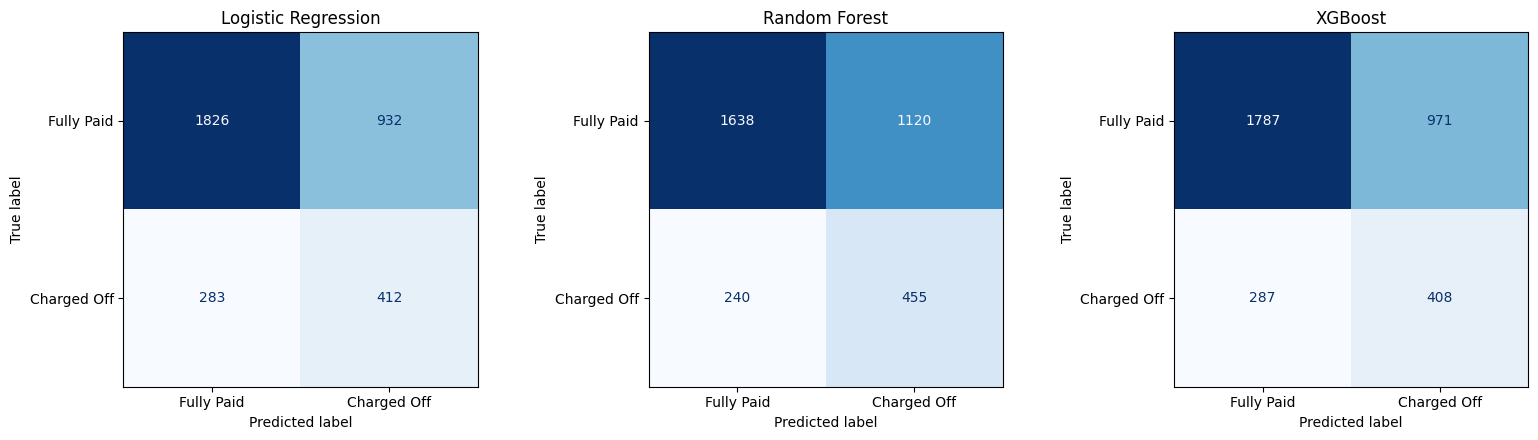

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16,4.5))
for ax, (nombre, (pred, prob)) in zip(axes, predicciones.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Fully Paid', 'Charged Off'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

**Comparación en test:**

| Modelo | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.6481 | 0.3065 | 0.5928 | **0.4041** | **0.6816** |
| Random Forest | 0.6061 | 0.2889 | **0.6547** | 0.4009 | 0.6800 |
| XGBoost | 0.6357 | 0.2959 | 0.5871 | 0.3934 | 0.6759 |
| Modelo trivial ("siempre paga") | 0.7987 | 0 | 0 | 0 | 0.50 |

*   **Accuracy no sirve para comparar:** el modelo trivial tiene el mayor accuracy (0.80) pero no detecta ni un solo default. Nuestros modelos sacrifican accuracy para detectar entre el 59% y el 65% de los incumplimientos.
*   **Sobreajuste:** la diferencia entre train y test es pequeña en los tres modelos (F1 de 0.018 a 0.026 y AUC de 0.022 a 0.028), así que **no hay sobreajuste relevante**. El ajuste de profundidad lo controló, mientras que el Random Forest sin límite de profundidad sí sobreajustaba.
*   **Subajuste:** incluso en el train, el AUC es solo de 0.70 a 0.71. Los modelos no logran separar mucho mejor las clases ni siquiera con los datos que ya vieron. **El límite no está en el algoritmo, sino en la información de las variables**: el desempeño está limitado por los datos (sesgo alto), no por la capacidad del modelo.
*   **Matrices de confusión:** Random Forest detecta más defaults (455 de 695), pero con más falsas alarmas (1,120). La regresión logística detecta 412 con 932 falsas alarmas, el mejor equilibrio de los tres.

## Best model selection

**Modelo seleccionado: Logistic Regression.** Se elige por cuatro razones:
1.  Tiene el **mejor F1** (0.4207 en CV y 0.4041 en test) y el **mejor AUC** (0.6997 en CV y 0.6816 en test). Ni Random Forest ni XGBoost la superan.
2.  Es el modelo con **menor brecha entre train y test**, es decir, el más estable.
3.  Es **interpretable**: en riesgo crediticio es necesario poder explicar por qué un préstamo se considera riesgoso (por ejemplo, ante un cliente o un regulador).
4.  Es el más simple y rápido de ejecutar en la aplicación.

**Contra los criterios de la fase 1:** el AUC ≥ 0.70 se cumple en validación cruzada (0.6997, prácticamente 0.70) y queda algo por debajo en test (0.6816), una diferencia que está dentro de la variabilidad normal entre particiones. El segundo criterio, que los modelos complejos superaran a la regresión logística, **no se cumplió**, y ese es un hallazgo en sí mismo: con estas variables, el riesgo se explica bien con una combinación lineal.

In [ ]:
mejor_nombre = 'Logistic Regression'
mejor_modelo = modelos_finales[mejor_nombre]
pred, prob = predicciones[mejor_nombre]
print(classification_report(y_test, pred, target_names=['Fully Paid', 'Charged Off']))

              precision    recall  f1-score   support

  Fully Paid       0.87      0.66      0.75      2758
 Charged Off       0.31      0.59      0.40       695

    accuracy                           0.65      3453
   macro avg       0.59      0.63      0.58      3453
weighted avg       0.75      0.65      0.68      3453



In [ ]:
filas = []
for umbral in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_u = (prob >= umbral).astype(int)
    filas.append([umbral, precision_score(y_test, pred_u), recall_score(y_test, pred_u),
                  f1_score(y_test, pred_u), pred_u.mean()])
pd.DataFrame(filas, columns=['Umbral', 'Precision', 'Recall', 'F1', 'Proporcion marcada como riesgo']).round(4)

,Umbral,Precision,Recall,F1,Proporcion marcada como riesgo
0,0.3,0.2346,0.9324,0.3749,0.7999
1,0.4,0.2625,0.7727,0.3918,0.5925
2,0.5,0.3065,0.5928,0.4041,0.3892
3,0.6,0.3595,0.4086,0.3825,0.2288
4,0.7,0.3897,0.2187,0.2802,0.1129


El modelo entrega una **probabilidad** de default y el umbral define a partir de qué valor se marca como riesgo. Con el umbral de 0.5 (el que maximiza el F1) se marca el 38.9% de los préstamos y se detecta el 59.3% de los defaults. Si la plataforma prefiere no perder incumplimientos, puede bajar el umbral a 0.4 y detectar el 77.3% de los defaults, a costa de marcar el 59.3% de los préstamos. Si prefiere aprobar más, puede subirlo a 0.6 y detectar el 40.9%. **El umbral es una decisión de negocio** que depende del costo de cada tipo de error. Esta tabla se presenta solo como ilustración: el modelo final mantiene el umbral de 0.5.

## Model interpretation

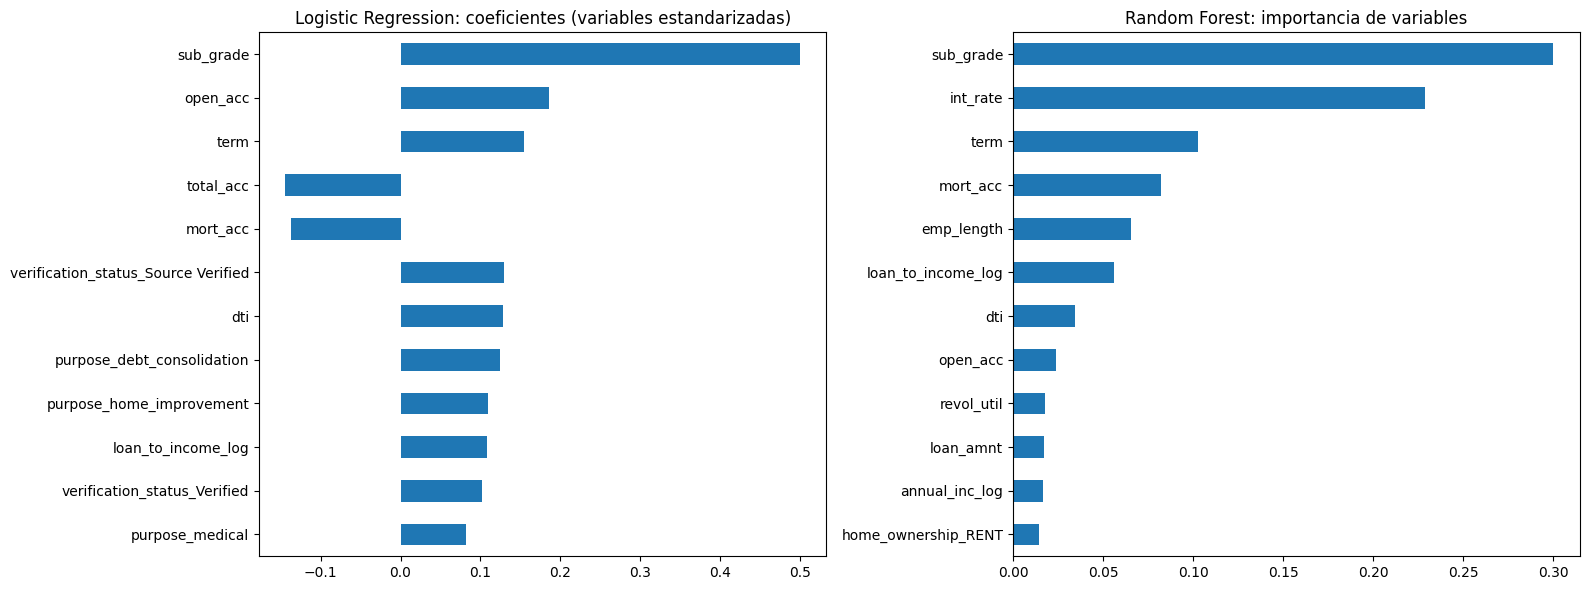

total_acc                             -0.145
mort_acc                              -0.137
home_ownership_OTHER                  -0.050
annual_inc_log                        -0.040
loan_amnt                             -0.036
emp_length                            -0.034
revol_bal_log                         -0.032
application_type_Joint App            -0.005
home_ownership_OWN                     0.004
purpose_major_purchase                 0.014
purpose_small_business                 0.022
int_rate                               0.025
revol_util                             0.034
purpose_credit_card                    0.064
home_ownership_RENT                    0.074
purpose_other                          0.076
purpose_medical                        0.081
verification_status_Verified           0.102
loan_to_income_log                     0.108
purpose_home_improvement               0.109
purpose_debt_consolidation             0.125
dti                                    0.128
verificati

In [ ]:
coeficientes = pd.Series(modelos_finales['Logistic Regression'].coef_[0], index=X.columns)
importancias = pd.Series(modelos_finales['Random Forest'].feature_importances_, index=X.columns)

plt.figure(figsize=(16,6))
plt.subplot(1,2,1)
coeficientes.reindex(coeficientes.abs().sort_values().index).tail(12).plot(kind='barh')
plt.title('Logistic Regression: coeficientes (variables estandarizadas)')
plt.subplot(1,2,2)
importancias.sort_values().tail(12).plot(kind='barh')
plt.title('Random Forest: importancia de variables')
plt.tight_layout()
plt.show()

print(coeficientes.sort_values().round(3))

Como las variables están estandarizadas, el coeficiente de la regresión logística indica cuánto cambia el riesgo (en log-odds) cuando la variable sube una desviación estándar. Si es positivo, aumenta el riesgo, y si es negativo, lo reduce.

*   **sub_grade (+0.500)** es por mucho el factor principal: cada escalón de calificación hacia G aumenta el riesgo. Le siguen **open_acc (+0.185)** y **term (+0.154)**. Los préstamos a 60 meses son más riesgosos, como mostró el EDA.
*   **dti (+0.128)**, **loan_to_income_log (+0.108)** y verification_status (Source Verified +0.129, Verified +0.102) aumentan el riesgo. Esto confirma tanto el valor de la variable creada en Feature Engineering como el patrón contraintuitivo de la verificación.
*   **total_acc (−0.145)** y **mort_acc (−0.137)** reducen el riesgo: un historial crediticio más largo y tener hipoteca indican mayor estabilidad. open_acc y total_acc tienen signos opuestos porque están correlacionadas (0.71): para un mismo historial total, tener más cuentas abiertas al mismo tiempo indica mayor exposición.
*   Los coeficientes de purpose se interpretan frente a la categoría de referencia (car). debt_consolidation (+0.125) y home_improvement (+0.109) son más riesgosos que un préstamo para carro.
*   int_rate tiene un coeficiente pequeño (+0.025) porque comparte casi toda su información con sub_grade (r = 0.975): el modelo le asigna el efecto a sub_grade.

**Random Forest coincide en lo esencial:** sub_grade (0.30) e int_rate (0.23) son las variables más importantes, seguidas de term, mort_acc, emp_length y loan_to_income_log. Que dos modelos tan distintos (uno lineal y otro de árboles) identifiquen los mismos factores da robustez a la conclusión.

## Conclusions

**Respuesta al problema:** sí es posible anticipar, con la información disponible al originar el préstamo, cuáles préstamos tienen más riesgo de incumplir, aunque **de forma parcial**. El modelo final (regresión logística con SMOTE) detecta el **59.3% de los préstamos que terminan en default** (412 de 695 en test) y ordena a los clientes por riesgo con un AUC de 0.68 a 0.70.

**Qué significa para la plataforma:** entre los préstamos que el modelo marca como riesgosos, el 30.7% termina en default, frente al 20.1% promedio. Es decir, concentra 1.5 veces más riesgo que una selección al azar. Entre los préstamos que el modelo considera seguros, el default baja a 13.4% (283 de 2,109). Si la plataforma no hubiera aprobado los préstamos marcados, la tasa de default de su cartera habría bajado de 20.1% a 13.4%. El costo es que el 33.8% de los buenos clientes (932 de 2,758) también quedan marcados. Por eso el modelo sirve mejor como **herramienta de apoyo** (por ejemplo, para revisar con más cuidado, cobrar una tasa mayor o pedir más garantías) que como regla automática de rechazo.

**Qué explica el riesgo:** la calificación crediticia (sub_grade e int_rate) y el plazo son, con diferencia, los factores principales. Les siguen el nivel de endeudamiento (dti), el tamaño del préstamo frente al ingreso (loan_to_income) y el número de cuentas. Esto es coherente con el EDA del primer semestre.

## Limitations and future work

**Limitaciones:**
*   **Información limitada:** el AUC en train también está cerca de 0.70, así que con estas 19 variables hay un límite en lo que cualquier modelo puede predecir. El incumplimiento depende también de eventos posteriores a la originación (desempleo, enfermedad, crisis) que no están en los datos.
*   **Muestra:** se usó una muestra de 30,000 de los 2.26 millones de préstamos. Los resultados son representativos de esa muestra.
*   **Sesgo de selección:** solo hay préstamos aprobados por LendingClub, así que el modelo no aprende sobre los solicitantes rechazados.
*   **Sesgo temporal:** los préstamos recientes (2017 y 2018) están subrepresentados entre los terminados, y las condiciones económicas de 2007 a 2018 pueden no repetirse.
*   **Dependencia de grade:** buena parte de la señal proviene de sub_grade e int_rate, que son el resultado del modelo de riesgo de la propia LendingClub. Nuestro modelo complementa, más que reemplaza, esa evaluación.
*   **Ingreso autoreportado** y verificación no aleatoria (verification_status).

**Mejoras futuras:**
*   Entrenar con el dataset completo o una muestra mayor, y validar con una partición temporal (entrenar con años anteriores y probar con años posteriores).
*   Incluir variables disponibles en la originación que no se usaron, como la antigüedad del historial crediticio (earliest_cr_line), las consultas recientes (inq_last_6mths), las moras previas (delinq_2yrs) o el FICO.
*   Definir el umbral con una matriz de costos real (pérdida por default frente a ganancia por préstamo bueno).
*   Calibrar las probabilidades, ya que SMOTE las desplaza hacia arriba respecto a la tasa real de default.

## Model export for deployment

Para el despliegue se guardan en un solo archivo (modelo_riesgo.joblib) todos los objetos que la aplicación necesita para repetir exactamente el mismo preprocesamiento: el modelo entrenado, el StandardScaler, las medianas de imputación, el orden de las columnas, las categorías válidas de purpose y la información que se muestra en la app (métricas de test, matriz de confusión y coeficientes). También se guardan los préstamos del conjunto de prueba en sus valores originales (prestamos_prueba.csv), para poder seleccionarlos en la app y comparar la predicción con el resultado real.

Si se ejecuta en Colab, los archivos quedan en el panel de archivos y se deben descargar para subirlos al repositorio.

In [ ]:
columnas_app = ['loan_amnt', 'term', 'sub_grade', 'int_rate', 'annual_inc', 'emp_length', 'home_ownership',
                'verification_status', 'purpose', 'application_type', 'dti', 'revol_util', 'revol_bal',
                'open_acc', 'total_acc', 'mort_acc']

artefactos = {
    'nombre_modelo': mejor_nombre,
    'modelo': mejor_modelo,
    'scaler': scaler,
    'pca': None,
    'medianas': medianas,
    'columnas': X.columns.tolist(),
    'purpose_validos': purpose_validos,
    'purpose_opciones': sorted(df_clean['purpose'].unique().tolist()),
    'umbral': 0.5,
    'tasa_default': y.mean(),
    'int_rate_por_sub_grade': df_clean.loc[X_train.index].groupby('sub_grade')['int_rate'].median().to_dict(),
    'metricas_test': tabla_test.loc[mejor_nombre, ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']].to_dict(),
    'matriz_confusion': confusion_matrix(y_test, pred).tolist(),
    'importancias': coeficientes.to_dict() if mejor_nombre == 'Logistic Regression' else importancias.to_dict(),
}

joblib.dump(artefactos, 'modelo_riesgo.joblib')
df_clean.loc[X_test.index, columnas_app + ['default']].to_csv('prestamos_prueba.csv', index=False)
print('Archivos generados: modelo_riesgo.joblib y prestamos_prueba.csv')

import sklearn
print('Versiones usadas (deben coincidir con requirements.txt):')
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__, '| joblib', joblib.__version__)

Archivos generados: modelo_riesgo.joblib y prestamos_prueba.csv
Versiones usadas (deben coincidir con requirements.txt):
scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6 | joblib 1.6.0


**Aplicación web en Streamlit.** Se organiza con la estructura vista en clase:

| Archivo | Rol |
|---|---|
| app.py | Frontend: interfaz de Streamlit (entrada de datos, botón Run, resultados y gráficas). |
| model.py | Backend: carga modelo_riesgo.joblib y aplica el mismo preprocesamiento del notebook (codificación ordinal, log, loan_to_income, agrupación de categorías, one-hot, imputación, escalado) antes de predecir. |
| modelo_riesgo.joblib | Modelo entrenado y objetos de preprocesamiento exportados desde este notebook. |
| prestamos_prueba.csv | 3,453 préstamos reales del conjunto de prueba, para la demostración. |
| requirements.txt | Librerías necesarias, con las versiones fijadas para que el modelo cargue igual que en el notebook. |

**Conexión con el modelo:** app.py nunca transforma datos por su cuenta. Solo recoge las entradas y llama a model.predecir(datos), que devuelve la probabilidad y la clase. Así, el preprocesamiento vive en un solo lugar y es idéntico al del entrenamiento. Se verificó que, al pasar los 3,453 préstamos de prueba por model.py, se obtiene exactamente la misma matriz de confusión y el mismo AUC (0.6816) que en este notebook.

**Funcionalidades:**
*   **Entrada de datos:** se puede seleccionar un préstamo real del conjunto de prueba o ingresar uno manualmente. Al elegir el sub_grade, la tasa de interés se sugiere automáticamente con la mediana de ese subgrado.
*   **Ejecución en vivo:** el botón Run ejecuta el modelo sobre los datos ingresados.
*   **Visualización:** alerta de riesgo alto o bajo, probabilidad de default comparada con el umbral y con la tasa promedio, resultado real (si el préstamo es del test), métricas del modelo, matriz de confusión y coeficientes que explican qué variables aumentan o reducen el riesgo.